# E111 · The path we were on: years of life Europe lost to COVID, and whether it came back

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: Eurostat, licensed CC BY 4.0 (Commission Decision 2011/833/EU), downloaded 2026-11-05/06: deaths by single year of age (`demo_magec`), population on 1 January by age (`demo_pjan`) and published life expectancy (`demo_mlexpec`) for the 27 EU countries, Iceland, Norway and Switzerland, 2000-2024. Both sexes together, in 20 age groups (0, 1-4, 5-9, ..., 85-89, 90+); built by `tools/build_e111_eurostat.py`, which keeps Eurostat's break-in-series flags (three census breaks are corrected in part A) |
| **You will learn** | The **Lee-Carter** model of mortality ($\log m = a + b\,k$) and its classic SVD-plus-random-walk forecast · an abridged **life table** and how to check it against official figures · census breaks in the population series, measured by age and corrected · Lee-Carter as one generative **negative-binomial** model in PyMC, pooled over 30 countries: softmax age sensitivities with zero-sum rows, a smoothness penalty over age, partially pooled improvement rates · a level the likelihood cannot see, shown failing with no divergence to warn · a hand-written likelihood, timed against PyMC's · a **counterfactual** ("the path we were on") pushed draw by draw through a nonlinear life table · a **backtest that fails** (46% inside a 90% fan) and a shared random-walk error as a model of the model's own error · bounce-back probabilities · Poisson against negative binomial · for the public: a **graded fan** on a tile-grid map of Europe, risk-equivalent ages as quantile dotplots, a 100-world swarm of excess deaths, a mortality carpet |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 111
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** How much life expectancy did my country lose to the pandemic, against where it
was heading, and is it back on that path?

**What we did.** We learned how fast death rates had been falling in 30 European countries in
2000-2019, small countries borrowing strength from large ones, and ran that trend on to 2024: "the
path we were on". Tested on 2015-2019, the method ran about half a year too optimistic, so we
widened the path by an error of that size.

**What we found.** In 2021 Europe's life expectancy was about 1.3 years below its path (89% range
0.6 to 1.9), and 4 years in Bulgaria. By 2024 the gap was about half a year. 17 of the 30
countries are *likely* (over 66%) still below their path; for the other 13 the chance is 45-65%,
which fits a full recovery or a small remaining gap.

**How sure are we.** It is *virtually certain* (>99%) that Europe was below its path in 2021, and
we have *high confidence* in that: the gap is several times the forecast's own error. It is
*likely* (74%) that Europe was still below its path in 2024, but we have *low confidence* in that
figure, because of the failed test.

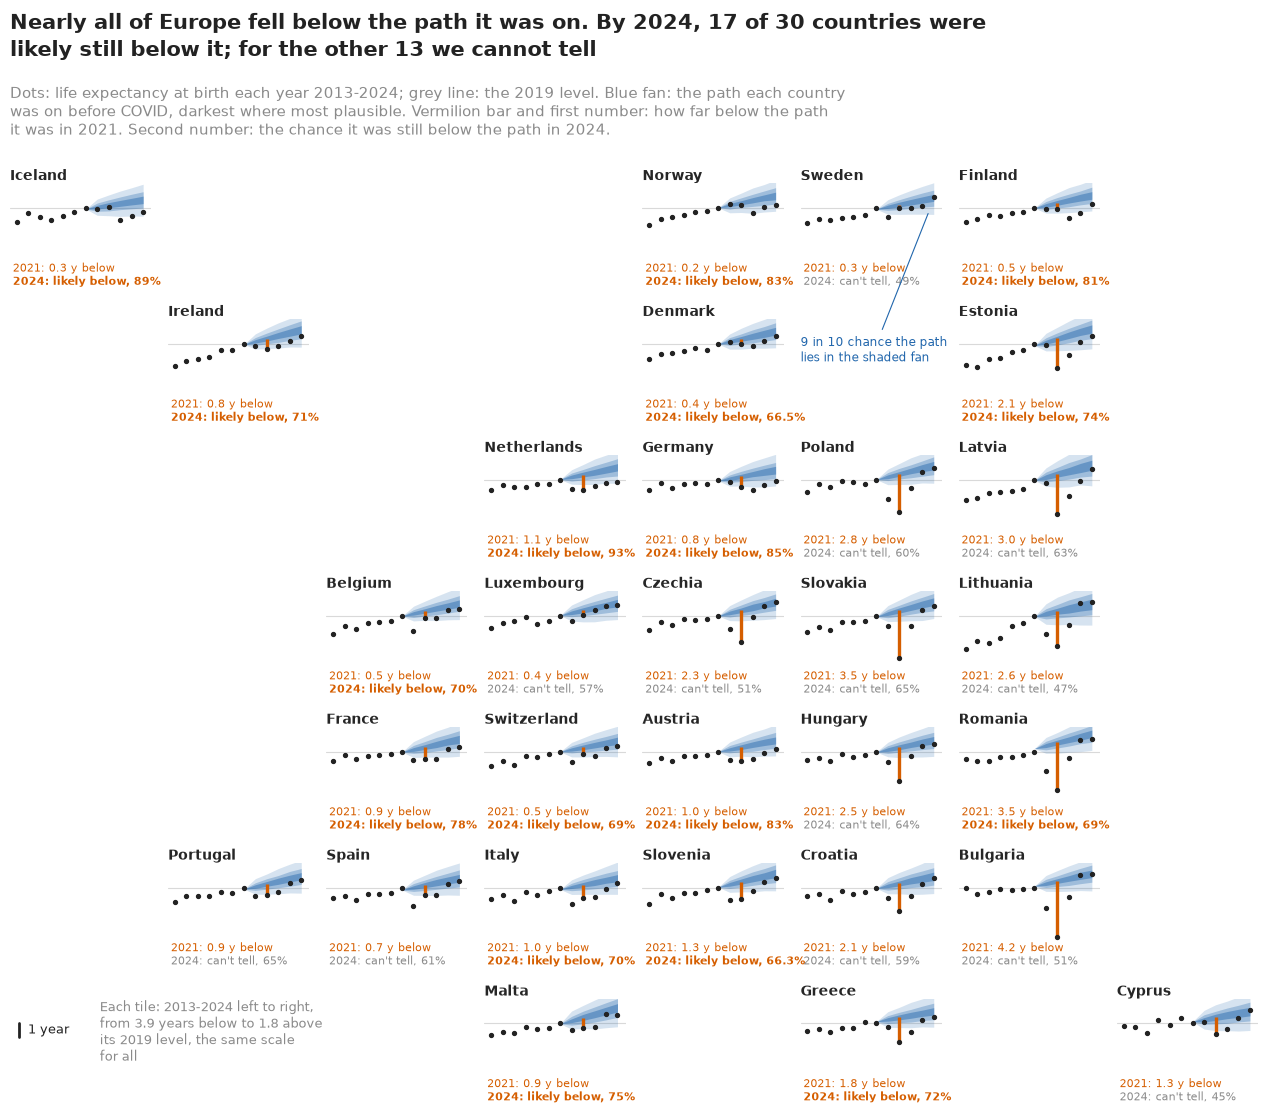

In [2]:
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Life expectancy at birth is the one mortality number most people understand: not how long anyone
will live, but how long a newborn would live if one year's death rates held for a lifetime, a
summary of a single year's mortality.

Before the pandemic life expectancy in most of Europe rose by two to three months a year, so a
fair comparison for 2021 is not 2019 but where 2021 would have been. The question this notebook
answers is how far each country fell below **the path it was on**, and whether by 2024 it had
returned to it. That path never happened, so it can only come from a model, and the model's
uncertainty is part of the answer.

The standard model of a mortality trend is Lee & Carter's (1992): the log death rate at age $x$ in
year $t$ is an age profile plus an age-specific sensitivity times a single period index, $\log
m_{xt} = a_x + b_x k_t$, with $k_t$ forecast as a random walk with drift. Lee and Carter fitted it
by singular value decomposition; Brouhns, Denuit & Vermunt (2002) gave it a Poisson likelihood,
and Czado, Delwarde & Denuit (2005) and Pedroza (2006) made it Bayesian, so that the forecast
carries the uncertainty of the fitted parameters as well as of future years; Wiśniowski et al.
(2015) used such components to forecast whole populations. Lee & Miller (2001), evaluating the
method's record, found an error where the fitted rates of the last year differ from the observed
ones, and recommended starting from the observed rates (the "jump-off"); we test that choice
below.

For the pandemic itself, Aburto, Schöley, Kashnitsky et al. (2022, *International Journal of
Epidemiology*) measured the 2020 losses in 29 countries against 2019 levels: life expectancy fell
in 27 of them, mostly through deaths above age 60. Schöley et al. (2022, *Nature Human Behaviour*)
carried the comparison into 2021 and found a rebound in western Europe while eastern Europe lost
more.

The plan is to build the path in steps and to test it before trusting it.

| part | question | tool |
|---|---|---|
| A | What do 25 years of European deaths look like? | rate surface, life table, census breaks |
| B | What does a Bayesian Lee-Carter add? | SVD and random walk; NB fit |
| C | How do 30 countries help each other? | pooled model, a failure, checks |
| D | Would the path have predicted 2015-2019? | a failed backtest and a shared European error |
| E | How far below the path did each country fall? | counterfactual life tables per draw |
| F | Has anyone come back? | bounce-back probabilities, Poisson against NB |
| G | How do we explain it to everyone? | a fan map, risk-equivalent ages, a swarm, a carpet |

## A · Thirty countries, twenty-five years

The data are Eurostat's deaths and populations by single year of age, built into one file by
`tools/build_e111_eurostat.py`. Exposure, the person-years at risk, is the average of the
populations on 1 January of the year and the next. Eurostat's oldest single ages stop at 85, 90 or
95 in some countries' early years, so the open group is 90+, built from Eurostat's totals; that
keeps all 30 countries. We use both sexes together.

In [3]:
data.describe("e111_eu_mortality")
RAW = data.load("e111_eu_mortality")
DF = RAW[RAW["sex"] == "T"]
print(RAW.shape, "rows;", DF["geo"].nunique(), "countries;", DF["year"].min(), "-",
      DF["year"].max())

e111_eu_mortality: One row per country, sex and year and single age (204,750 rows): geo (Eurostat code: AT ... SK, IS, NO, CH; EL is Greece), sex (T total, F, M), year (2000-2024), age (0-89, and 90 meaning 90+), deaths (float: unknown-age deaths spread pro rata), exposure (person-years: mean of the 1 January populations of years t and t+1), pop (1 January population of year t, sex T rows only), e0_eurostat (Eurostat's life expectancy at birth for the country, sex and year, repeated on every age row), pop_break (1 where Eurostat flags the year's 1 January population 'b', break in series). Exposures are as published, breaks included. Flagged breaks 2000-2025 (whole-population step against the usual change): CZ 2021 (-1.9% vs +0.3%), PL 2021 (-2.3% vs -0.3%), DE 2011 (-1.9% vs -0.1%), HR 2001 (-4.5%), PL 2000 and 2010, BE 2011-12, CH 2011, DE 2023, FR 2012/2014, HU 2012, IT 2019, LU 2012/2017, SI 2008 (each under 1% beyond the usual change). NaN where Eurostat lacks the cells: Latvia 200

In [4]:
EDGES = [0, 1] + list(range(5, 95, 5))  # 0, 1-4, 5-9, ..., 85-89, 90+: 20 groups
LABELS = ["0", "1-4"] + [f"{a}-{a + 4}" for a in range(5, 90, 5)] + ["90+"]
WIDTH = np.diff(EDGES + [np.inf])
MID = np.array([0.5, 3.0] + [x + 2.5 for x in range(5, 90, 5)] + [92.5])
NAMES = {"AT": "Austria", "BE": "Belgium", "BG": "Bulgaria", "CY": "Cyprus", "CZ": "Czechia",
         "DE": "Germany", "DK": "Denmark", "EE": "Estonia", "EL": "Greece", "ES": "Spain",
         "FI": "Finland", "FR": "France", "HR": "Croatia", "HU": "Hungary", "IE": "Ireland",
         "IT": "Italy", "LT": "Lithuania", "LU": "Luxembourg", "LV": "Latvia", "MT": "Malta",
         "NL": "Netherlands", "PL": "Poland", "PT": "Portugal", "RO": "Romania", "SE": "Sweden",
         "SI": "Slovenia", "SK": "Slovakia", "IS": "Iceland", "NO": "Norway", "CH": "Switzerland"}


def cube(df):
    """Deaths and exposure as (geo, year, age group) arrays; a group with any missing age is NaN."""
    geos = list(dict.fromkeys(df["geo"]))
    years = np.sort(df["year"].unique())
    g = df.assign(grp=np.searchsorted(EDGES, df["age"], side="right") - 1,
                  miss=df["deaths"].isna() | df["exposure"].isna())
    agg = g.groupby(["geo", "year", "grp"])[["deaths", "exposure"]].sum(min_count=1)
    agg[g.groupby(["geo", "year", "grp"])["miss"].any()] = np.nan
    agg = agg.reindex(pd.MultiIndex.from_product([geos, years, range(len(LABELS))]))
    shape = (len(geos), len(years), len(LABELS))
    e0 = df.groupby(["geo", "year"])["e0_eurostat"].first()
    e0 = e0.reindex(pd.MultiIndex.from_product([geos, years]))
    return (agg["deaths"].to_numpy().reshape(shape), agg["exposure"].to_numpy().reshape(shape),
            geos, years, e0.to_numpy().reshape(shape[:2]))


D, E, GEOS, YEARS, E0_EUROSTAT = cube(DF)
C, NY, A = D.shape
YI = {int(y): i for i, y in enumerate(YEARS)}
print(f"{C} countries x {NY} years x {A} age groups; missing cells: {int(np.isnan(D).sum())} "
      f"(all before 2013: {bool(np.isnan(D[:, YI[2013]:]).sum() == 0)})")
print("deaths in the 30 countries (millions):",
      {y: round(float(np.nansum(D[:, YI[y]])) / 1e6, 2)
       for y in (2000, 2010, 2019, 2020, 2021, 2022, 2023, 2024)})
print("smallest countries in 2019, people (thousands) and deaths:",
      {g: (round(E[GEOS.index(g), YI[2019]].sum() / 1e3),
           round(float(D[GEOS.index(g), YI[2019]].sum()))) for g in ("IS", "MT", "LU", "CY", "EE")})
print(f"Germany 2019: {D[GEOS.index('DE'), YI[2019]].sum():,.0f} deaths")

30 countries x 25 years x 20 age groups; missing cells: 82 (all before 2013: True)
deaths in the 30 countries (millions): {2000: 4.25, 2010: 4.42, 2019: 4.76, 2020: 5.3, 2021: 5.41, 2022: 5.28, 2023: 4.97, 2024: 4.93}
smallest countries in 2019, people (thousands) and deaths: {'IS': (361, 2275), 'MT': (504, 3688), 'LU': (620, 4283), 'CY': (896, 6239), 'EE': (1327, 15401)}
Germany 2019: 939,520 deaths


Thirty countries, 25 years and 20 age groups make 15,000 cells; the 82 missing ones, all before
2013, are left out of the likelihood. Deaths grew slowly from 4.25 million in 2000 to 4.76 million
in 2019 as the population aged, jumped to 5.3 and 5.4 million in 2020 and 2021, and were still
near 4.9 million in 2024. Iceland, with 361,000 people, had about 2,300 deaths in 2019, only a
handful in most age groups below 50; Germany had close to a million. That difference is why
pooling will matter.

The figure shows each age group's log death rate against its 2000-2002 average, in Spain and in
Bulgaria. Blue means lower: Spain's rates fell steadily at every age, fastest among children and
young adults (where they halved or better), slowest in the very old. Bulgaria's fell much less
above age 40. The pandemic is the vertical stripe: faint in Spain in 2020 at old ages, a red
column in Bulgaria in 2021, strongest from age 25 to 70, with rates up to 20-30% above their 2000
level at ages where they had been falling for twenty years.

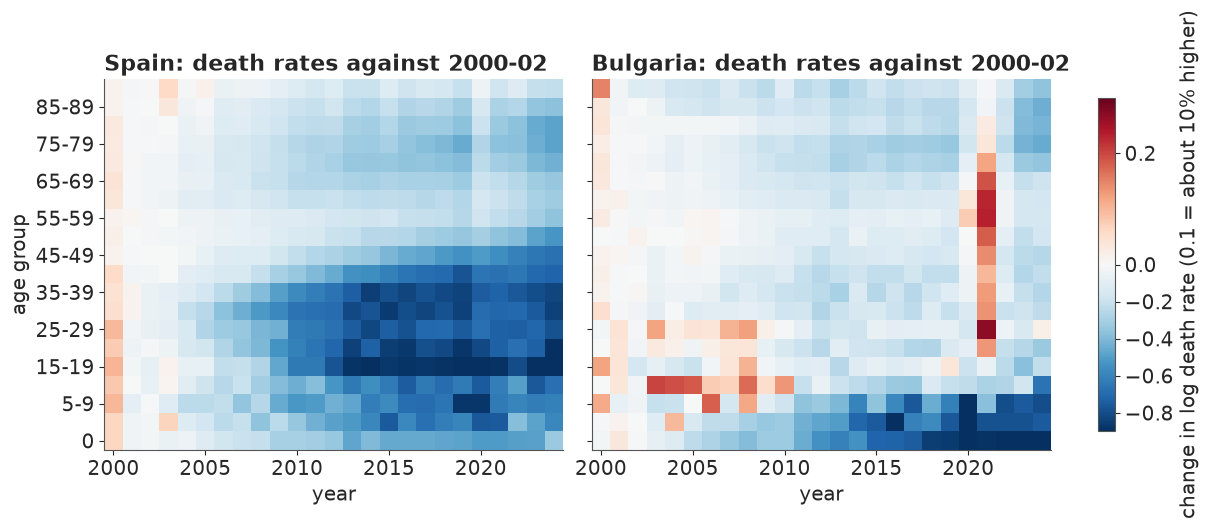

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
norm = TwoSlopeNorm(vcenter=0, vmin=-0.9, vmax=0.3)
for ax, g in zip(axes, ("ES", "BG")):
    c = GEOS.index(g)
    lm = np.log(D[c] / E[c])
    rel = lm - lm[:3].mean(0)  # change in log death rate since 2000-2002, per age group
    im = ax.pcolormesh(YEARS, np.arange(A), rel.T, cmap="RdBu_r", norm=norm, shading="nearest")
    ax.set_title(f"{NAMES[g]}: death rates against 2000-02", loc="left")
    ax.set_xlabel("year")
axes[0].set_yticks(range(0, A, 2), LABELS[::2])
axes[0].set_ylabel("age group")
fig.colorbar(im, ax=axes, label="change in log death rate (0.1 = about 10% higher)", shrink=0.9);

### Life expectancy from a schedule of death rates

Everything later is measured in life expectancy, so we need a life table: the function that turns
20 death rates into one number. For an age group of width $n$ starting at $x$, the death rate
$m_x$ becomes a probability of dying within the group,

$$ q_x = \frac{n\, m_x}{1 + (n - a_x)\, m_x}, $$

where $a_x$ is the average time lived in the group by those who die in it: half the width for most
groups, and for the first two the Coale-Demeny rules, because infant deaths crowd into the first
weeks. Survivors are $l_{x+n} = l_x (1 - q_x)$ from $l_0 = 1$, person-years lived in the group are
$L_x = n\, l_{x+n} + a_x (l_x - l_{x+n})$, the open group 90+ lives $l_{90}/m_{90}$, and life
expectancy at birth is the sum of all the $L_x$. This *abridged* table works on five-year groups;
we check it against Eurostat's published figures, computed on single years.

In [6]:
def a0_cd(m0):
    """Coale-Demeny West a0 and 4a1, averaged over the male and female formulas (both sexes)."""
    a0 = np.where(m0 >= 0.107, 0.34, 0.5 * (0.045 + 2.684 * m0 + 0.053 + 2.800 * m0))
    a1 = np.where(m0 >= 0.107, 1.3565, 0.5 * (1.651 - 2.816 * m0 + 1.522 - 1.518 * m0))
    return a0, a1


def e0_abridged(m):
    """Life expectancy at birth from rates m[..., 20] on the groups 0, 1-4, ..., 85-89, 90+."""
    m = np.asarray(m, float)
    n = WIDTH[:-1]
    a0, a1 = a0_cd(m[..., 0])
    ax = np.broadcast_to(n / 2, m[..., :-1].shape).copy()
    ax[..., 0], ax[..., 1] = a0, a1
    q = np.clip(n * m[..., :-1] / (1 + (n - ax) * m[..., :-1]), 0, 1)
    lx = np.concatenate([np.ones(m.shape[:-1] + (1,)), np.cumprod(1 - q, axis=-1)], axis=-1)
    Lx = n * lx[..., 1:] + ax * (lx[..., :-1] - lx[..., 1:])
    return Lx.sum(-1) + lx[..., -1] / m[..., -1]


err = e0_abridged(D / E) - E0_EUROSTAT  # on Eurostat's own populations, as published
print(f"ours minus Eurostat, all {np.isfinite(err).sum()} country-years: "
      f"mean {np.nanmean(err):+.2f}, range {np.nanmin(err):+.2f} to {np.nanmax(err):+.2f} years")
print("the same error in 2021 minus in 2019: at most "
      f"{np.nanmax(np.abs(err[:, YI[2021]] - err[:, YI[2019]])):.2f} years in any country")

ours minus Eurostat, all 736 country-years: mean -0.06, range -0.55 to +0.16 years
the same error in 2021 minus in 2019: at most 0.16 years in any country


Over 736 country-years, our table is 0.06 years below Eurostat's on average and never more than
0.55 below or 0.16 above. More to the point, the error barely moves from year to year: the change
from 2019 to 2021 agrees with Eurostat's to within 0.16 years in every country, and differences
between life tables built the same way are all we report.

### Breaks in the population series

The check against Eurostat cannot see one problem, because Eurostat uses the same populations.
When a census finds fewer people than the registers had been counting, the population on 1 January
drops in one step, flagged as a *break in series*. A 2% step in the denominators becomes a 2% step
in every death rate, which a trend model reads as mortality. For each flagged break we measure the
step by age: a cohort's growth across the break year divided by its growth in the years on either
side. Where the whole step is larger than 1%, we put the populations before the break on the
census level, age group by age group, before anything is fitted.

In [7]:
POP = DF.pivot_table(index=["geo", "year"], columns="age", values="pop")  # 1 January, ages 0..90+
DTH = DF.pivot_table(index=["geo", "year"], columns="age", values="deaths", dropna=False)
GRP = np.searchsorted(EDGES, np.arange(91), side="right") - 1


def break_ratio(g, t, adjust=False):
    """Census level over the old level, by age group, for a break between 1 January t-1 and t.

    Also returns the step in the whole population and the deaths-weighted step at ages 60-89.
    adjust=True adds each cohort's deaths back, so that the ratios measure migration and the
    break only, not a year of unusual mortality."""
    X, Dx = POP.loc[g], DTH.loc[g]

    def coh(y):  # cohort ratio P_y(a) / P_(y-1)(a-1): survival and migration over year y-1
        p0 = X.loc[y - 1, 0:88].to_numpy()
        r = X.loc[y, 1:89].to_numpy() / p0
        r90 = X.loc[y, 90] / X.loc[y - 1, [89, 90]].sum()
        if adjust:  # the cohort's deaths in year y-1: half those at its two ages, all of 90+
            r = r + 0.5 * (Dx.loc[y - 1, 0:88].to_numpy() + Dx.loc[y - 1, 1:89].to_numpy()) / p0
            r90 = r90 + (0.5 * Dx.loc[y - 1, 89] + Dx.loc[y - 1, 90]) / X.loc[y - 1, [89, 90]].sum()
        return np.r_[np.nan, r, r90]

    with np.errstate(divide="ignore", invalid="ignore"):  # Hungary's 2006-11 have no ages 85+
        r = coh(t) / ((coh(t - 1) + coh(t + 1)) / 2)
    r[0] = r[1]
    w = X.loc[t].to_numpy()
    yrs = [t - 2, t - 1, t, t + 1]
    tot = X.loc[yrs, X.loc[yrs].notna().all(axis=0)].sum(axis=1)  # the ages present in all four
    step = (tot[t] / tot[t - 1]) / ((tot[t - 1] / tot[t - 2] + tot[t + 1] / tot[t]) / 2)
    dw = Dx.loc[t, 60:89].to_numpy()
    ok = np.isfinite(r[60:90]) & np.isfinite(dw)
    old = np.average(r[60:90][ok], weights=dw[ok])
    rg = np.array([np.nanmean(r[GRP == j]) if np.isnan(w[GRP == j]).any()
                   else np.average(r[GRP == j], weights=w[GRP == j]) for j in range(A)])
    return rg, step, old


E_RAW, E = E, E.copy()  # the published exposures, and a copy we correct
fixed = {}
for (g, t), _ in DF[DF["pop_break"] == 1].groupby(["geo", "year"]):
    if t - 2 < YEARS[0]:
        print(f"break {g} {t}: not measurable (no year t-2 in the data)")
        continue
    r, step, old = break_ratio(g, t)
    old_adj = break_ratio(g, t, adjust=True)[2]
    print(f"break {g} {t}: whole population {step - 1:+.1%} beyond the usual change; ages 60-89 "
          f"{old - 1:+.1%} ({old_adj - 1:+.1%} with deaths added back)", end="")
    if abs(step - 1) > 0.01:
        c = GEOS.index(g)
        E[c, YEARS < t - 1] *= r          # years whose exposure is all before the break
        E[c, YI[t - 1]] *= (1 + r) / 2    # the year that straddles it
        fixed[f"{g} {t}"] = r - 1
        print("  -> corrected", end="")
    print()
print(pd.DataFrame(fixed, index=LABELS).T.iloc[:, [3, 5, 7, 9, 13, 15, 17, 19]].round(3)
      .to_string())
E0_OBS = e0_abridged(D / E)  # (geo, year), observed, no uncertainty
e0_raw = e0_abridged(D / E_RAW)
for g, y in (("PL", 2019), ("CZ", 2019), ("DE", 2009)):
    print(f"{NAMES[g]} {y}: life expectancy {e0_raw[GEOS.index(g), YI[y]]:.2f} on the published "
          f"populations, {E0_OBS[GEOS.index(g), YI[y]]:.2f} on the census level")
for g in ("CZ", "PL"):  # the 2021 steps measured with 2020's and 2021's deaths taken out
    c, r_adj = GEOS.index(g), break_ratio(g, 2021, adjust=True)[0]
    Ea = E_RAW[c, YI[2019]] * r_adj
    print(f"{NAMES[g]} 2021 step with deaths added back: 2019 life expectancy "
          f"{e0_abridged(D[c, YI[2019]] / Ea):.2f}")
show =["ES", "IT", "SE", "DE", "PL", "BG", "SK", "NO"]
print(pd.DataFrame({y: E0_OBS[[GEOS.index(g) for g in show], YI[y]]
                    for y in (2010, 2019, 2020, 2021, 2022, 2024)},
                   index=[NAMES[g] for g in show]).round(2).to_string())

break BE 2011: whole population +0.7% beyond the usual change; ages 60-89 -0.0% (+0.0% with deaths added back)
break BE 2012: whole population -0.3% beyond the usual change; ages 60-89 +0.2% (+0.0% with deaths added back)
break CH 2011: whole population +0.0% beyond the usual change; ages 60-89 -0.6% (-0.6% with deaths added back)
break CZ 2021: whole population -2.2% beyond the usual change; ages 60-89 -0.7% (-0.4% with deaths added back)  -> corrected
break DE 2011: whole population -1.9% beyond the usual change; ages 60-89 -1.4% (-1.3% with deaths added back)  -> corrected
break DE 2023: whole population -0.4% beyond the usual change; ages 60-89 -1.1% (-0.9% with deaths added back)
break FR 2012: whole population -0.0% beyond the usual change; ages 60-89 -0.0% (-0.2% with deaths added back)
break FR 2014: whole population +0.4% beyond the usual change; ages 60-89 +0.1% (+0.2% with deaths added back)
break HR 2001: not measurable (no year t-2 in the data)
break HU 2012: whole populat

Seventeen country-years carry the flag. Two cannot be measured, since the comparison needs the
year before last, and neither reaches the fit: Poland's 2000 break falls before any exposure we
use, and Croatia's 2001 (-4.5% in the published totals) touches only 2000, whose deaths are
missing. Three steps are large, about 2% beyond the usual change, and these we correct: Czechia
and Poland in 2021 (their censuses) and Germany in 2011. They are largest among young adults,
2-5%, people who emigrated without leaving the registers; 0.7-1.4% at 60-89, where most deaths
are; and 3-4% in Czechia and Poland and 10% in Germany at 90+, where registers are known to keep
some who have died or left, though the cohort ratio is also noisiest there. Poland's 2019 life
expectancy falls from 77.88 to 77.69 on the census level, Czechia's from 79.24 to 79.11, and
Germany's 2009 value from 80.10 to 79.86. Left uncorrected, the Polish and Czech steps of 0.19 and
0.13 years would fall inside 2020-2021, where the path would read them as pandemic loss.

Two checks on this rule. The 2021 ratios compare survival over 2020 with survival over 2019 and
2021; adding each cohort's deaths back, so that they measure only migration and the break, moves
the corrected 2019 values by 0.02-0.04 years. And the total can hide a break. Germany's 2023 break
(the 2022 census) is only -0.4% overall, because about a million people arrived from Ukraine in
2022, but at 60-89 it is about -1%, as large as the corrected ones. We leave it as published and
test what it does in part F. The other breaks are within 0.6% at 60-89.

The observed values already outline the story. Spain, Italy and Sweden fell in 2020 and were above
2019 by 2024. Poland, Bulgaria and Slovakia fell further in 2021 - Bulgaria 3.7 years below 2019 -
and then rebounded sharply. Germany fell slowly through 2022 and in 2024 was still just below its
2019 level; Norway did not fall in 2020 at all. But "back to 2019" is not "back on the path": a
country that would have gained a year by 2024 and is level with 2019 is a year short.

## B · One country, the classic way and the Bayesian way

### Lee-Carter by singular value decomposition

Lee and Carter's model for one country is

$$ \log m_{xt} = a_x + b_x k_t + \varepsilon_{xt}, \qquad \sum_x b_x = 1, \quad \sum_t k_t = 0. $$

$a_x$ is the average log rate at age $x$; $k_t$ is a single index of how high mortality is in year
$t$; $b_x$ says how strongly age $x$ follows it. The two constraints fix what the product $b_x
k_t$ leaves free: multiplying $b$ by 2 and dividing $k$ by 2 changes nothing, and nor does adding
a constant to $k$ and moving it into $a$. With the constraints, $a_x$ is the row mean of the log
rates, and $b$ and $k$ are the first singular vectors of what is left. We fit Spain for 2000-2019.

Spain 2000-2019: the first component explains 96.8% of the variation in log rates around a_x
k falls by -0.62 a year (sd of yearly changes 0.51); b is largest at 15-19 (0.095) and smallest at 90+ (0.020)


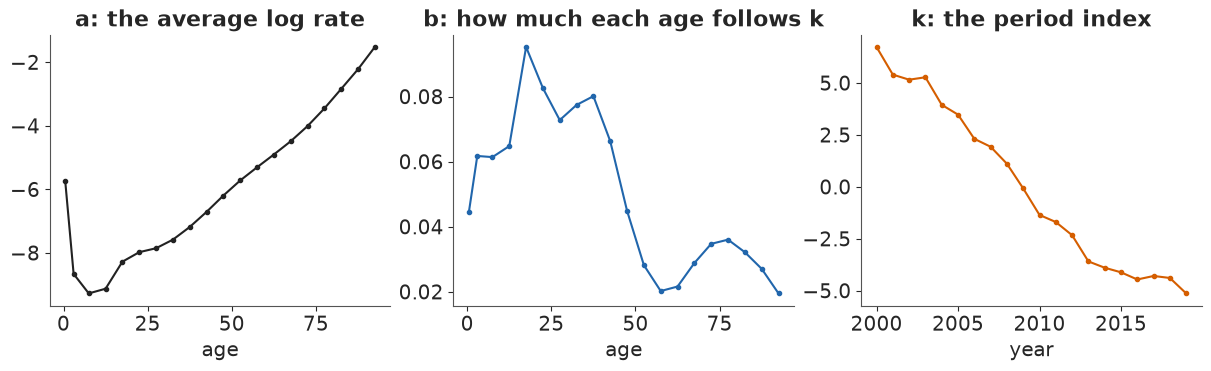

In [8]:
FIT0, FIT1 = 2000, 2019
fit_years = (YEARS >= FIT0) & (YEARS <= FIT1)


def svd_lee_carter(Dc, Ec):
    """Lee-Carter by SVD for one country: a (age), b (age, sums to 1), k (year)."""
    lm = np.log((Dc + 0.5) / Ec)
    ok = np.isfinite(lm)
    a = np.nanmean(lm, axis=0)
    R = np.where(ok, lm - a, 0.0)
    U, s, Vt = np.linalg.svd(R, full_matrices=False)
    b, k = Vt[0], U[:, 0] * s[0]
    if b.sum() < 0:
        b, k = -b, -k
    return a, b / b.sum(), k * b.sum(), s[0] ** 2 / (s ** 2).sum()


cE = GEOS.index("ES")
a_s, b_s, k_s, share = svd_lee_carter(D[cE, fit_years], E[cE, fit_years])
d_s = np.diff(k_s)
drift_s, sig_s = d_s.mean(), d_s.std(ddof=1)
print(f"Spain 2000-2019: the first component explains {share:.1%} of the variation in log rates "
      "around a_x")
print(f"k falls by {drift_s:.2f} a year (sd of yearly changes {sig_s:.2f}); b is largest at "
      f"{LABELS[int(np.argmax(b_s))]} ({b_s.max():.3f}) and smallest at "
      f"{LABELS[int(np.argmin(b_s))]} ({b_s.min():.3f})")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].plot(MID, a_s, "o-", color=INK, ms=3)
axes[0].set(title="a: the average log rate", xlabel="age")
axes[1].plot(MID, b_s, "o-", color=HI, ms=3)
axes[1].set(title="b: how much each age follows k", xlabel="age")
axes[2].plot(YEARS[fit_years], k_s, "o-", color=LO, ms=3)
axes[2].set(title="k: the period index", xlabel="year");

One component explains 97% of the variation, which is why the model has survived thirty years.
Spain's $k$ falls by 0.62 a year, with yearly changes that scatter by 0.51 around that drift. The
age pattern $b$ peaks at 15-19 and stays high to about 45, then drops to a fifth of that at 55-64
and again at 90+: young-adult mortality fell fastest, old-age mortality slowest. Because $b$ sums
to one, a fall of 1 in $k$ lowers the log rate at age $x$ by $b_x$: about 9.5% at 15-19 and 2% at
90+.

Lee and Carter's forecast treats $k$ as a random walk with drift,

$$ k_{T+h} = k_T + h\,\delta + \sigma \sum_{j=1}^{h} \epsilon_j, \qquad
   \epsilon_j \sim N(0, 1), $$

with $\delta$ and $\sigma$ the mean and standard deviation of the past yearly changes. A 90% band
for $k$ is $k_T + h\delta \pm 1.645\, \sigma \sqrt{h}$, and since life expectancy is a monotone
function of $k$, the band maps straight into life expectancy.

In [9]:
H5 = np.arange(1, 6)
PROJ = np.arange(2020, 2025)
z90 = 1.645
k_cl = (k_s[-1] + drift_s * H5[None, :]
        + np.array([[-z90], [0], [z90]]) * sig_s * np.sqrt(H5)[None, :])
e0_cl = np.sort(e0_abridged(np.exp(a_s[None, None, :] + b_s[None, None, :] * k_cl[:, :, None])),
                axis=0)
print("classic projection of Spain's life expectancy, 5% / 50% / 95%:")
print(pd.DataFrame(e0_cl.T, index=PROJ, columns=["5%", "50%", "95%"]).round(2).to_string())

classic projection of Spain's life expectancy, 5% / 50% / 95%:
         5%    50%    95%
2020  83.27  83.54  83.80
2021  83.36  83.74  84.11
2022  83.48  83.94  84.39
2023  83.61  84.13  84.65
2024  83.74  84.33  84.91


The classic path for Spain rises from 83.5 years in 2020 to 84.3 in 2024, with a 90% band 0.5
years wide in 2020 and 1.2 in 2024. The band treats $a$, $b$ and the drift as known, although
twenty years pin the drift down only to about $\pm 0.15$, and the SVD treats a log rate built from
3 deaths as as reliable as one built from 30,000.

### The same model as a generative one

The Bayesian version writes down how the death counts arise:

$$ D_{xt} \sim \text{NegBin}\big(E_{xt}\, e^{a_x + b_x k_t},\ \phi\big), \qquad
   k_t = k_{t-1} + \delta + \sigma_k \epsilon_t, $$

so the random walk is part of the model rather than a second step. A Poisson count would say the
only noise is the luck of who dies; the negative binomial adds extra variation of relative size
$1/\sqrt{\phi}$, for the flu winters and heat waves that move whole years. The constraints become
a parameterisation: $b = \text{softmax}(\beta)$ is positive and sums to one, with each row of
$\beta$ summing to zero; $k$ is built from its yearly increments and then centred. A random-walk
penalty on neighbouring $\beta$ (an RW1 prior over age, scale $\tau_b$) keeps the age pattern
smooth unless the data insist. The priors on the drift, $N(-0.4, 0.4)$, and on $\sigma_k$,
log-normal around 0.3, are wide on the scale of what has happened in Europe; we check them in part
C.

The function below builds this model for one country or many, and the next fits Spain alone. Every
chain starts at the SVD fit.

In [10]:
def lee_carter_model(Dg, Eg, geos, years, lik="nb", pooled=True, zero_sum=True):
    """Bayesian Lee-Carter on a dense (geo, year, age) grid; NaN cells are left out."""
    Cg, Tg, Ag = Dg.shape
    ok = np.isfinite(Dg) & np.isfinite(Eg)
    Dd = np.where(ok, np.round(np.nan_to_num(Dg)), 0).astype(np.int64)
    lE = np.log(np.where(ok, Eg, 1.0))
    coords = {"geo": geos, "age": LABELS, "year": years, "step": years[1:]}
    with pm.Model(coords=coords) as model:
        if pooled:
            a_eu = pm.Normal("a_eu", -5.0, 3.0, dims="age")
            s_a = pm.HalfNormal("s_a", 0.5, dims="age")
            a = pm.Normal("a", a_eu, s_a, dims=("geo", "age"))  # centred: the data are strong
            beta_eu = pm.ZeroSumNormal("beta_eu", sigma=1.5, dims="age")
            centre = beta_eu[None, :]
        else:
            a = pm.Normal("a", -5.0, 3.0, dims=("geo", "age"))
            centre = 0.0
        # log-sensitivities with zero-sum rows (the softmax ignores a common shift), and an RW1
        # smoothness penalty over age on their deviation from the European pattern
        if zero_sum:
            beta_r = pm.Flat("beta_r", shape=(Cg, Ag - 1))
            beta = pm.Deterministic(
                "beta", pt.concatenate([beta_r, -beta_r.sum(axis=1, keepdims=True)], axis=1),
                dims=("geo", "age"))
        else:  # Failure 1: every row of beta free, so a constant added to a row changes nothing
            beta = pm.Flat("beta", dims=("geo", "age"))
        dev = beta - centre
        dev = dev - dev.mean(axis=1, keepdims=True)
        tau_b = pm.HalfNormal("tau_b", 0.3)
        pm.Potential("b_smooth", -0.5 * pt.sum(pt.sqr(pt.diff(dev, axis=1) / tau_b))
                     - Cg * (Ag - 1) * pt.log(tau_b))
        b = pm.Deterministic("b", pt.special.softmax(beta, axis=1), dims=("geo", "age"))
        if pooled:
            drift_eu = pm.Normal("drift_eu", -0.4, 0.4)
            s_drift = pm.HalfNormal("s_drift", 0.3)
            z_drift = pm.Normal("z_drift", 0, 1, dims="geo")
            drift = pm.Deterministic("drift", drift_eu + s_drift * z_drift, dims="geo")
            mu_lsk = pm.Normal("mu_lsk", np.log(0.3), 1.0)
            s_lsk = pm.HalfNormal("s_lsk", 0.5)
            z_sk = pm.Normal("z_sk", 0, 1, dims="geo")
            sigma_k = pm.Deterministic("sigma_k", pt.exp(mu_lsk + s_lsk * z_sk), dims="geo")
        else:
            drift = pm.Normal("drift", -0.4, 0.4, dims="geo")
            sigma_k = pm.LogNormal("sigma_k", np.log(0.3), 1.0, dims="geo")
        inc = pm.Normal("inc", drift[:, None], sigma_k[:, None], dims=("geo", "step"))
        kraw = pt.concatenate([pt.zeros((Cg, 1)), pt.cumsum(inc, axis=1)], axis=1)
        k = pm.Deterministic("k", kraw - kraw.mean(axis=1, keepdims=True), dims=("geo", "year"))
        eta = a[:, None, :] + b[:, None, :] * k[:, :, None] + lE
        mu = pt.exp(eta)
        if lik in ("nb", "nb_pymc"):
            if pooled:
                mu_lphi = pm.Normal("mu_lphi", np.log(1000.0), 1.5)
                s_lphi = pm.HalfNormal("s_lphi", 1.0)
                z_phi = pm.Normal("z_phi", 0, 1, dims="geo")
                phi = pm.Deterministic("phi", pt.exp(mu_lphi + s_lphi * z_phi), dims="geo")
            else:
                phi = pm.LogNormal("phi", np.log(1000.0), 1.5, dims="geo")
            ph = phi[:, None, None]
            if lik == "nb":  # NB2 log-likelihood written out, constants in the data dropped
                lp = (pt.gammaln(Dd + ph) - pt.gammaln(ph) + ph * pt.log(ph)
                      - (ph + Dd) * pt.log(ph + mu) + Dd * eta)
            else:            # the same through PyMC's own distribution, for the timing below
                lp = pm.logp(pm.NegativeBinomial.dist(mu=mu, alpha=ph), Dd)
        else:
            lp = Dd * eta - mu
        pm.Potential("lik", pt.sum(lp * ok))
    # start every chain from the SVD fit of each country
    init_a, init_b, init_k = [], [], []
    for c in range(Cg):
        a_c, b_c, k_c, _ = svd_lee_carter(Dg[c], Eg[c])
        a_c = np.where(np.isfinite(a_c), a_c, np.nanmean(np.log((Dg + 0.5) / Eg), axis=(0, 1)))
        init_a.append(a_c)
        init_b.append(np.log(np.clip(b_c, 1e-3, None)))
        init_k.append(k_c)
    lb = np.array(init_b)
    lb -= lb.mean(1, keepdims=True)
    init = {"a": np.array(init_a), "inc": np.diff(np.array(init_k), axis=1)}
    init.update({"beta_r": lb[:, :-1]} if zero_sum else {"beta": lb})
    if pooled:
        init.update(a_eu=np.array(init_a).mean(0), beta_eu=lb.mean(0))
    return model, init, ok


def fit(model, init, draws=1000, label=""):
    t0 = time.time()
    with model:
        idata = pm.sample(draws=draws, tune=400, chains=4, random_seed=RANDOM_SEED, initvals=init,
                          progressbar=False)
    TIMES[label] = time.time() - t0
    ss = idata.sample_stats
    print(f"[{label}] {TIMES[label]:.0f} s; {idata.posterior.attrs['tuning_steps']} tuning steps, "
          f"{idata.posterior.sizes['draw']} draws x 4 chains; "
          f"divergences {int(ss['diverging'].sum())}; "
          f"tree depth {int(ss['depth'].min())}-{int(ss['depth'].max())}")
    return idata


def check(idata, names, model):
    """r_hat and bulk ESS for the named quantities, then over every free variable, one at a time."""
    rows = {}

    def row(v):
        x = idata.posterior[v]
        n = x.size // (x.sizes["chain"] * x.sizes["draw"])
        return n, float(az.rhat(x).max()), float(az.ess(x).min())

    for v in names:
        rows[v] = row(v)
    free = [row(rv.name) for rv in model.free_RVs]
    n_free = sum(v.size for v in model.initial_point().values())  # on the sampling scale
    rows["ALL free variables"] = (n_free, max(f[1] for f in free), min(f[2] for f in free))
    print(pd.DataFrame(rows, index=["values", "max r_hat", "min ESS (bulk)"]).T.round(3)
          .to_string())


m_es, init_es, _ = lee_carter_model(D[[cE]][:, fit_years], E[[cE]][:, fit_years], ["ES"],
                                    YEARS[fit_years], pooled=False)
id_es = fit(m_es, init_es, label="Spain alone")
check(id_es, ["a", "b", "k", "drift", "sigma_k", "phi", "tau_b"], m_es)

[Spain alone] 9 s; 400 tuning steps, 1000 draws x 4 chains; divergences 0; tree depth 4-5


                    values  max r_hat  min ESS (bulk)
a                     20.0      1.004        7057.755
b                     20.0      1.002        3973.959
k                     20.0      1.003        2210.740
drift                  1.0      1.002        5930.683
sigma_k                1.0      1.001        2447.530
phi                    1.0      1.001        4747.355
tau_b                  1.0      1.001        5161.481
ALL free variables    62.0      1.004        1493.379


Spain alone is a small model (62 parameters, 400 cells) and samples cleanly under nutpie: no
divergences, r_hat at most 1.004, thousands of effective draws. Below we compare it with the SVD
and project it forward in NumPy: for each posterior draw, run $k$ on from 2019 with that draw's
drift and $\sigma_k$, rebuild the death rates, and push them through the life table. The life
table is nonlinear, so the uncertainty has to go through it draw by draw rather than being applied
to a point estimate.

drift: SVD -0.62; posterior -0.61 (89%: -0.77 to -0.46)
sigma_k: SVD 0.51; posterior 0.44; phi 1302
Bayesian projection of Spain, 5% / 50% / 95% (and the classic band's width):
         5%    50%    95%  width  classic width  observed
2020  83.34  83.60  83.87   0.54           0.53     82.22
2021  83.41  83.80  84.17   0.75           0.75     83.05
2022  83.52  83.99  84.42   0.90           0.91     83.05
2023  83.63  84.18  84.69   1.07           1.05     83.83
2024  83.78  84.37  84.96   1.17           1.16     84.05
2019: observed 83.57, fitted 83.40 (Bayesian), 83.34 (SVD)


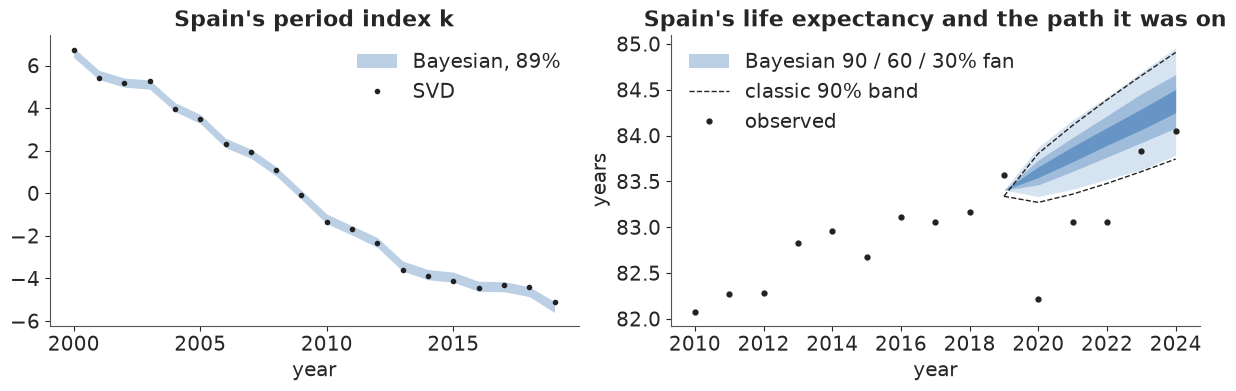

In [11]:
po = id_es.posterior
k_b = po["k"].values.reshape(-1, fit_years.sum())
print(f"drift: SVD {drift_s:.2f}; posterior {float(po['drift'].mean()):.2f} "
      f"(89%: {np.quantile(po['drift'], 0.055):.2f} to {np.quantile(po['drift'], 0.945):.2f})")
print(f"sigma_k: SVD {sig_s:.2f}; posterior {float(po['sigma_k'].mean()):.2f}; "
      f"phi {float(po['phi'].median()):.0f}")


def project_k(k_last, drift, sigma_k, H, rng_):
    """Random walk with drift from the last fitted year: (S, C, H)."""
    eps = rng_.standard_normal(k_last.shape + (H,))
    return (k_last[..., None] + drift[..., None] * np.arange(1, H + 1)
            + sigma_k[..., None] * np.cumsum(eps, axis=-1))


def thin(idata, names, n, rng_):
    """n draws of each variable as arrays with the draws first (float32)."""
    S = idata.posterior.sizes["chain"] * idata.posterior.sizes["draw"]
    pick = rng_.choice(S, n, replace=False) if n < S else np.arange(S)
    out = {}
    for v in names:
        x = idata.posterior[v].values
        out[v] = x.reshape((S,) + x.shape[2:])[pick].astype(np.float32)
    return out


P_es = thin(id_es, ["a", "b", "k", "drift", "sigma_k"], 1000, np.random.default_rng(1))
ks_es = project_k(P_es["k"][:, :, -1], P_es["drift"], P_es["sigma_k"], 5, np.random.default_rng(2))
e0_es = e0_abridged(np.exp(P_es["a"][:, :, None, :]
                           + P_es["b"][:, :, None, :] * ks_es[..., None]))[:, 0]
bq = np.quantile(e0_es, [0.05, 0.5, 0.95], axis=0)
print("Bayesian projection of Spain, 5% / 50% / 95% (and the classic band's width):")
print(pd.DataFrame({"5%": bq[0], "50%": bq[1], "95%": bq[2], "width": bq[2] - bq[0],
                    "classic width": e0_cl[2] - e0_cl[0],
                    "observed": E0_OBS[cE, [YI[y] for y in PROJ]]}, index=PROJ)
      .round(2).to_string())
fit19_es = float(np.median(e0_abridged(np.exp(P_es["a"] + P_es["b"] * P_es["k"][:, :, -1:]))))
fit19_cl = float(e0_abridged(np.exp(a_s + b_s * k_s[-1])))
print(f"2019: observed {E0_OBS[cE, YI[2019]]:.2f}, fitted {fit19_es:.2f} (Bayesian), "
      f"{fit19_cl:.2f} (SVD)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
lo_, hi_ = np.quantile(k_b, [0.055, 0.945], axis=0)
ax.fill_between(YEARS[fit_years], lo_, hi_, color=HI, alpha=0.3, lw=0, label="Bayesian, 89%")
ax.plot(YEARS[fit_years], k_s, "o", color=INK, ms=3, label="SVD")
ax.set(title="Spain's period index k", xlabel="year")
ax.legend(frameon=False)
ax = axes[1]
xs = np.r_[2019, PROJ]
for lvl, al in [(0.9, 0.18), (0.6, 0.30), (0.3, 0.45)]:
    q_ = np.quantile(e0_es, [(1 - lvl) / 2, (1 + lvl) / 2], axis=0)
    ax.fill_between(xs, np.r_[fit19_es, q_[0]], np.r_[fit19_es, q_[1]], color=HI, alpha=al, lw=0,
                    label="Bayesian 90 / 60 / 30% fan" if lvl == 0.6 else None)
ax.plot(xs, np.r_[fit19_cl, e0_cl[0]], color=INK, lw=1, ls="--")
ax.plot(xs, np.r_[fit19_cl, e0_cl[2]], color=INK, lw=1, ls="--", label="classic 90% band")
ax.plot(YEARS[YI[2010]:], E0_OBS[cE, YI[2010]:], "o", color=INK, ms=3.5, label="observed")
ax.set(title="Spain's life expectancy and the path it was on", xlabel="year", ylabel="years")
ax.legend(frameon=False, loc="upper left");

The posterior of $k$ hugs the SVD estimate, and the drift agrees (-0.61 against -0.62; 89%
interval -0.77 to -0.46). The surprise is the width of the forecast: the Bayesian 90% fan is 0.54
years wide in 2020 and 1.17 in 2024, against 0.53 and 1.16 for the classic band. Parameter
uncertainty widened the fan, but the year-to-year noise shrank by about as much ($\sigma_k$ 0.44
against 0.51), because the negative binomial explains part of each year's wobble as noise in the
counts rather than movement of the index. Both bands start from their *fitted* 2019 values, 83.40
(Bayesian) and 83.34 (SVD), about 0.2 years below the observed 83.57.

Against this path, Spain's 2020 life expectancy (82.2) is 1.4 years below the median, far outside
the fan; by 2024 it was 84.05, inside the fan but 0.3 below its middle.

## C · Thirty countries, pooled

### The model

With 30 countries we give every parameter a country index and let the countries share what they
plausibly share:

$$ a_{xc} \sim N(a^{EU}_x, s_{a,x}), \qquad
   \beta_{c} - \beta^{EU} \sim \text{RW1 over age}(\tau_b), \qquad
   \delta_c \sim N(\delta^{EU}, s_\delta), \qquad
   \log \sigma_{k,c} \sim N(\mu_\sigma, s_\sigma), \qquad \log \phi_c \sim N(\mu_\phi, s_\phi). $$

Each country's age profile and sensitivities vary around European ones, and its improvement rate,
volatility and overdispersion are partially pooled. For Germany, with a million deaths a year, the
data overwhelm all of this; for Iceland and Malta the European values carry real weight. The
likelihood covers 11,918 cells with 1,896 parameters.

First a check on the two priors that drive the forecast: holding Spain's SVD age pattern fixed, we
draw a drift and a $\sigma_k$ from the pooled priors and run $k$ for 19 years.

In [12]:
# what the priors on the period index say about life expectancy, before any data: hold Spain's SVD
# a and b fixed, draw drift and sigma_k from the pooled priors, and run k over twenty years
pr = np.random.default_rng(3)
n_pr = 2000
drift_pr = pr.normal(-0.4, 0.4, n_pr) + np.abs(pr.normal(0, 0.3, n_pr)) * pr.standard_normal(n_pr)
sk_pr = np.exp(pr.normal(np.log(0.3), 1.0, n_pr)
               + np.abs(pr.normal(0, 0.5, n_pr)) * pr.standard_normal(n_pr))
k_pr = np.cumsum(drift_pr[:, None] + sk_pr[:, None] * pr.standard_normal((n_pr, 19)), axis=1)
gain = (e0_abridged(np.exp(a_s + b_s * (k_s[0] + k_pr[:, -1:])))
        - e0_abridged(np.exp(a_s + b_s * k_s[0])))
print(f"prior: change in life expectancy over 2000-2019, 5% / 50% / 95%: "
      f"{np.quantile(gain, 0.05):+.1f} / {np.median(gain):+.1f} / "
      f"{np.quantile(gain, 0.95):+.1f} years "
      f"(Spain's observed change: {E0_OBS[cE, YI[2019]] - E0_OBS[cE, YI[2000]]:+.1f})")

prior: change in life expectancy over 2000-2019, 5% / 50% / 95%: -4.2 / +2.7 / +7.8 years (Spain's observed change: +4.4)


The prior allows anything from a 4-year fall to an 8-year rise over two decades, with Spain's real
gain of 4.4 years comfortably inside: weak, but not absurd.

### Failure 1: a level nobody can see

The softmax returns the same $b$ whatever constant is added to a row of $\beta$, so with every row
free that constant has no likelihood at all, and the smoothness penalty, built on differences,
does not see it either. The cell below refits Spain alone that way.

In [13]:
m_free, init_free, _ = lee_carter_model(D[[cE]][:, fit_years], E[[cE]][:, fit_years], ["ES"],
                                        YEARS[fit_years], pooled=False, zero_sum=False)
id_free = fit(m_free, init_free, draws=500, label="Spain, free beta rows")
check(id_free, ["beta", "b", "k", "drift"], m_free)
print("mean of beta's row in each chain:",
      id_free.posterior["beta"].mean(("draw", "age")).values.ravel().round(1))
del id_free, m_free

[Spain, free beta rows] 11 s; 400 tuning steps, 500 draws x 4 chains; divergences 0; tree depth 3-10


                    values  max r_hat  min ESS (bulk)
beta                  20.0      1.878           5.739
b                     20.0      1.009        1635.010
k                     20.0      1.005        1446.488
drift                  1.0      1.005        2594.506
ALL free variables    63.0      1.878           5.739
mean of beta's row in each chain: [ 7.9 26.8 -7.3  6.8]


The chains wander along the flat direction, each to its own level of $\beta$ (their row means
differ by tens): r_hat near 1.9 and about 6 effective draws, while $b$, $k$ and the drift, which
the data touch, have r_hat at most 1.01. No divergence warns, but the trees reach depth 10, the
sampler's limit. Rows of $\beta$ that sum to zero (the 20th is minus the sum of the first 19)
remove the direction, and the pooled model below also uses centred country effects, since every
country has hundreds of informative cells (E25's lesson).

A second, smaller lesson is speed. The negative-binomial log-likelihood, written out by hand,

$$ \log p(D \mid \mu, \phi) = \log\Gamma(D + \phi) - \log\Gamma(\phi) + \phi \log\phi
   - (\phi + D)\log(\phi + \mu) + D \log\mu + \text{const}, $$

takes $\log \mu$ directly from the linear predictor and drops the data-only terms. The cell times
one log density and gradient on the pooled grid under nutpie's Numba backend, against PyMC's own
`NegativeBinomial` and against a Poisson count.

In [14]:
def time_logp(lik, n=100):
    """Milliseconds per log density + gradient of the pooled model at its start point."""
    m_, _, _ = lee_carter_model(D[:, fit_years], E[:, fit_years], GEOS, YEARS[fit_years], lik=lik)
    f = m_.logp_dlogp_function(ravel_inputs=True, mode="NUMBA")
    f.set_extra_values({})
    x = np.concatenate([v.ravel() for v in m_.initial_point().values()])
    f(x)  # compile and warm up
    t0 = time.perf_counter()
    for _ in range(n):
        f(x)
    return (time.perf_counter() - t0) / n * 1e3


T_LOGP = {lik: time_logp(lik) for lik in ("nb_pymc", "nb", "pois")}
print({k: f"{v:.2f} ms" for k, v in T_LOGP.items()},
      f"-> written out {T_LOGP['nb_pymc'] / T_LOGP['nb']:.1f}x faster than PyMC's; "
      f"{T_LOGP['nb'] / T_LOGP['pois']:.0f}x a Poisson gradient")

{'nb_pymc': '1.48 ms', 'nb': '0.82 ms', 'pois': '0.10 ms'} -> written out 1.8x faster than PyMC's; 8x a Poisson gradient


Written out, the negative binomial is nearly twice as fast as PyMC's version, and still about 8
times the cost of a Poisson gradient: the log-gamma terms are the price of the extra noise.

In [15]:
m_main, init_main, ok_main = lee_carter_model(D[:, fit_years], E[:, fit_years], GEOS,
                                              YEARS[fit_years])
print(f"{int(ok_main.sum()):,} cells in the likelihood, {int((~ok_main).sum())} left out; "
      f"{sum(v.size for v in m_main.initial_point().values()):,} parameters")
id_main = fit(m_main, init_main, label="pooled NB 2000-2019")
check(id_main, ["a_eu", "a", "beta_eu", "b", "k", "drift", "drift_eu", "s_drift", "sigma_k",
                "tau_b", "phi", "mu_lphi"], m_main)

11,918 cells in the likelihood, 82 left out; 1,896 parameters


[pooled NB 2000-2019] 75 s; 400 tuning steps, 1000 draws x 4 chains; divergences 0; tree depth 5-5


                    values  max r_hat  min ESS (bulk)
a_eu                  20.0      1.004        5968.702
a                    600.0      1.006        4866.093
beta_eu               20.0      1.005         305.309
b                    600.0      1.012         394.666
k                    600.0      1.009         445.543
drift                 30.0      1.005        1373.383
drift_eu               1.0      1.001        1791.157
s_drift                1.0      1.000         911.091
sigma_k               30.0      1.007         523.334
tau_b                  1.0      1.000        1976.072
phi                   30.0      1.002        2871.843
mu_lphi                1.0      1.019         160.573
ALL free variables  1896.0      1.019         160.573


One to two minutes of sampling, no divergences, every transition at tree depth 5, and r_hat at
most 1.02 over all 1,896 free parameters, not only the ones listed. The weakest mixers are the
European sensitivity pattern $\beta^{EU}$ (about 300 effective draws) and the mean log
overdispersion $\mu_\phi$ (about 160): enough for what we use them for, and the quantities the
projection needs ($a$, $b$, $k$, the drifts and $\sigma_k$) all have about 400 or more.

European drift -0.50 (sd between countries s_drift 0.084); tau_b 0.21
phi (NB size) from {'RO': 150, 'NO': 5687} median over countries 1434
            pop 2019 (M)  SVD drift  pooled drift  sigma_k
Iceland             0.36      -0.28         -0.46     0.36
Malta               0.50      -0.09         -0.42     0.33
Luxembourg          0.62      -0.70         -0.56     0.43
Cyprus              0.90      -0.43         -0.55     0.68
Estonia             1.33      -0.81         -0.59     0.55
Latvia              1.91      -0.39         -0.53     0.59
smallest moves: {'Switzerland': 0.0, 'Italy': 0.0, 'Netherlands': 0.01, 'Slovenia': 0.01, 'Belgium': 0.01}
moves of the four largest: {'Germany': 0.04, 'France': 0.05, 'Italy': 0.0, 'Spain': 0.07}


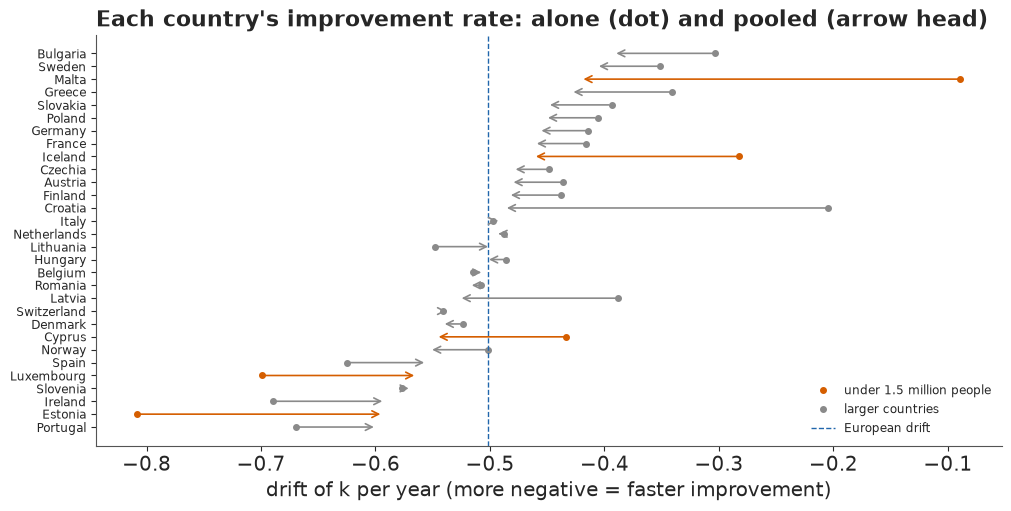

In [16]:
po = id_main.posterior
drift_m = po["drift"].mean(("chain", "draw")).values
k_svd = [svd_lee_carter(D[c, fit_years], E[c, fit_years])[2] for c in range(C)]
drift_svd = np.array([(k[-1] - k[0]) / (fit_years.sum() - 1) for k in k_svd])
print(f"European drift {float(po['drift_eu'].mean()):.2f} (sd between countries s_drift "
      f"{float(po['s_drift'].mean()):.3f}); tau_b {float(po['tau_b'].mean()):.2f}")
print("phi (NB size) from", {g: round(float(po['phi'].sel(geo=g).mean())) for g in
                             (GEOS[int(np.argmin(po['phi'].mean(('chain', 'draw')).values))],
                              GEOS[int(np.argmax(po['phi'].mean(('chain', 'draw')).values))])},
      f"median over countries {np.median(po['phi'].mean(('chain', 'draw')).values):.0f}")
pop19 = E[:, YI[2019]].sum(-1)
order = np.argsort(pop19)
print(pd.DataFrame({"pop 2019 (M)": pop19 / 1e6, "SVD drift": drift_svd, "pooled drift": drift_m,
                    "sigma_k": po["sigma_k"].mean(("chain", "draw")).values},
                   index=[NAMES[g] for g in GEOS]).iloc[order[:6]].round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
srt = np.argsort(drift_m)
for i, c in enumerate(srt):
    ax.annotate("", (drift_m[c], i), (drift_svd[c], i),
                arrowprops=dict(arrowstyle="->", color=LO if pop19[c] < 1.5e6 else MUTED, lw=1.2))
    ax.plot(drift_svd[c], i, "o", color=LO if pop19[c] < 1.5e6 else MUTED, ms=4)
ax.axvline(float(po["drift_eu"].mean()), color=HI, lw=1, ls="--")
ax.plot([], [], "o", color=LO, ms=4, label="under 1.5 million people")
ax.plot([], [], "o", color=MUTED, ms=4, label="larger countries")
ax.plot([], [], color=HI, lw=1, ls="--", label="European drift")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
move = np.abs(drift_m - drift_svd)
print("smallest moves:", {NAMES[GEOS[c]]: round(float(move[c]), 2) for c in np.argsort(move)[:5]})
print("moves of the four largest:", {NAMES[GEOS[c]]: round(float(move[c]), 2)
                                     for c in np.argsort(-pop19)[:4]})
ax.set_yticks(range(C), [NAMES[GEOS[c]] for c in srt], fontsize=8.5)
ax.set_xlabel("drift of k per year (more negative = faster improvement)")
ax.set_title("Each country's improvement rate: alone (dot) and pooled (arrow head)", loc="left");

### What pooling does to small countries

The European drift is -0.50 a year and countries spread around it with a standard deviation of
only 0.08, much less than the SVD drifts suggest (-0.09 to -0.81). Most of that spread was noise.
The arrows show each country's SVD drift moving to its pooled value, with countries under 1.5
million people in vermilion. Malta, whose SVD drift of -0.09 would mean almost no improvement in
twenty years, moves to -0.42; Iceland from -0.28 to -0.46; Luxembourg and Estonia, which looked
like Europe's fastest improvers, come back from -0.70 and -0.81 to -0.56 and -0.59. Italy,
Switzerland, the Netherlands and Belgium sit on their own estimates, and the four largest
countries move by 0.07 or less. This is the point of the hierarchy: a country with a few thousand
deaths a year cannot tell its own trend from a run of good or bad years.

The overdispersion runs from $\phi \approx 150$ in Romania to about 5,700 in Norway, with a median
near 1,400: extra noise of 1/sqrt(1,400), under 3%, in a typical cell. Small as that is, it
matters, because a cell with 30,000 expected deaths has Poisson noise of only 0.6%.

### Does the fit reproduce the data?

For every fitted cell we simulate deaths from the posterior, with negative-binomial noise, and ask
how often the observed count falls inside the 90% interval; then we compare fitted and observed
life expectancy.

In [17]:
# posterior predictive check on the fitted cells: does the 90% interval of deaths cover 90%?
P_main = thin(id_main, ["a", "b", "k", "drift", "sigma_k", "phi"], 1000, np.random.default_rng(4))
Df, Ef = D[:, fit_years], E[:, fit_years]


def ppc_coverage(P, lik, rng_):
    m_ = np.exp(P["a"][:, :, None, :] + P["b"][:, :, None, :] * P["k"][:, :, :, None])
    m_ = m_.astype(np.float64)
    mu_ = m_ * np.nan_to_num(Ef)[None]
    expected = mu_.mean(0)
    if lik == "nb":
        ph = P["phi"][:, :, None, None].astype(np.float64)
        mu_ = rng_.gamma(ph, mu_ / ph)
    y = rng_.poisson(mu_)
    lo_, hi_ = np.quantile(y, [0.05, 0.95], axis=0)
    inside = np.where(ok_main, (Df >= lo_) & (Df <= hi_), np.nan)
    by_size = {}
    for a, b in ((0, 10), (10, 1000), (1000, np.inf)):  # small cells are covered by discreteness
        cell = (expected >= a) & (expected < b) & ok_main
        by_size[f"{a}-{b}"] = (round(float(cell.sum() / ok_main.sum()), 2),
                               round(float(np.nanmean(inside[cell])), 3))
    return np.nanmean(inside), by_size, m_


cov_nb, size_nb, m_fit = ppc_coverage(P_main, "nb", np.random.default_rng(5))
e0_fit = e0_abridged(m_fit)  # (S, C, T)
E0_FIT19 = np.median(e0_fit[:, :, -1], 0)
gap19 = E0_FIT19 - E0_OBS[:, YI[2019]]
rmse = np.sqrt(np.nanmean((np.median(e0_fit, 0) - E0_OBS[:, fit_years]) ** 2, axis=1))
print(f"90% predictive intervals of deaths cover {cov_nb:.1%} of the {int(ok_main.sum()):,} cells")
print("by expected deaths in the cell (share of cells, coverage):", size_nb)
print(f"fitted minus observed e0 in 2019: {gap19.min():+.2f} to {gap19.max():+.2f} years; "
      f"root-mean-square error of fitted e0 over 2000-2019: {rmse.min():.2f}-{rmse.max():.2f} "
      "years per country, largest in "
      f"{', '.join(NAMES[GEOS[c]] for c in np.argsort(rmse)[-3:][::-1])}")
del m_fit

90% predictive intervals of deaths cover 92.6% of the 11,918 cells
by expected deaths in the cell (share of cells, coverage): {'0-10': (0.03, 0.953), '10-1000': (0.48, 0.907), '1000-inf': (0.49, 0.942)}
fitted minus observed e0 in 2019: -0.18 to +0.22 years; root-mean-square error of fitted e0 over 2000-2019: 0.04-0.24 years per country, largest in Romania, Cyprus, Iceland


The 90% intervals cover 92.6% of cells. Split by expected deaths, cells under 10 (3% of cells) are
covered 95%, helped by discreteness, those of 10 to 1,000 91% and those over 1,000 94%: the large
cells, where one overdispersion per country would fail first, are not under-covered. The
root-mean-square error of fitted life expectancy over 2000-2019 is 0.04-0.24 years per country,
largest in Romania, Cyprus and Iceland; in 2019, where the projection starts, the fitted value is
within -0.18 to +0.22 years of the observed one.

## D · Does the path predict? A test before the pandemic

So far the model has been checked only on the years it was fitted to. The natural test of a path:
pretend it is 2014, fit 2000-2014, project 2015-2019, and see whether about 90% of the 150
country-years land inside the 90% fans.

In [18]:
bt_years = (YEARS >= 2000) & (YEARS <= 2014)
m_bt, init_bt, _ = lee_carter_model(D[:, bt_years], E[:, bt_years], GEOS, YEARS[bt_years])
id_bt = fit(m_bt, init_bt, draws=500, label="backtest NB 2000-2014")
check(id_bt, ["b", "k", "drift", "sigma_k", "phi", "beta_eu", "mu_lphi"], m_bt)
P_bt = thin(id_bt, ["a", "b", "k", "drift", "sigma_k"], 2000, np.random.default_rng(6))
del id_bt, m_bt

[backtest NB 2000-2014] 63 s; 400 tuning steps, 500 draws x 4 chains; divergences 0; tree depth 5-5


                    values  max r_hat  min ESS (bulk)
b                    600.0      1.032         140.079
k                    450.0      1.029         172.550
drift                 30.0      1.008         541.002
sigma_k               30.0      1.020         186.562
phi                   30.0      1.003        1415.209
beta_eu               20.0      1.033         171.341
mu_lphi                1.0      1.055         163.274
ALL free variables  1746.0      1.055          80.870


In [19]:
BT = np.arange(2015, 2020)
k_bt = project_k(P_bt["k"][:, :, -1], P_bt["drift"], P_bt["sigma_k"], 5, np.random.default_rng(7))
e0_bt = e0_abridged(np.exp(P_bt["a"][:, :, None, :] + P_bt["b"][:, :, None, :] *
                           k_bt[..., None]))  # S, C, 5
obs_bt = E0_OBS[:, [YI[y] for y in BT]]
lo_bt, med_bt, hi_bt = np.quantile(e0_bt, [0.05, 0.5, 0.95], axis=0)
z_bt = (obs_bt - med_bt) / e0_bt.std(0)
inside = (obs_bt >= lo_bt) & (obs_bt <= hi_bt)
print(f"2015-2019: the 90% fan covers {inside.mean():.0%} of {inside.size} country-years; "
      f"{(obs_bt < lo_bt).mean():.0%} fall below it and {(obs_bt > hi_bt).mean():.0%} above")
W19 = pop19 / pop19.sum()
print(pd.DataFrame({"covered": inside.mean(0), "below": (obs_bt < lo_bt).mean(0),
                    "mean z": z_bt.mean(0), "sd of z across countries": z_bt.std(0),
                    "observed - path (pop-weighted, years)":
                        (W19[:, None] * (obs_bt - med_bt)).sum(0)},
                   index=BT).round(2).to_string())


def trend(c, y0, y1):
    """Least-squares slope of observed life expectancy, years per year."""
    yy = np.arange(y0, y1 + 1)
    v = E0_OBS[c, [YI[y] for y in yy]]
    ok = np.isfinite(v)
    return np.polyfit(yy[ok], v[ok], 1)[0]


tr = np.array([[trend(c, 2000, 2019), trend(c, 2010, 2019)] for c in range(C)])
cG = GEOS.index("DE")
print(f"life expectancy trend 2010-2019 flatter than 2000-2019 in {(tr[:, 1] < tr[:, 0]).sum()} "
      f"of {C} countries; Germany {tr[cG, 1]:.3f} against {tr[cG, 0]:.3f} years a year")

2015-2019: the 90% fan covers 46% of 150 country-years; 54% fall below it and 0% above
      covered  below  mean z  sd of z across countries  observed - path (pop-weighted, years)
2015     0.33   0.67   -1.95                      1.46                                  -0.40
2016     0.70   0.30   -1.10                      0.95                                  -0.28
2017     0.40   0.60   -1.65                      0.94                                  -0.49
2018     0.30   0.70   -1.77                      0.95                                  -0.62
2019     0.57   0.43   -1.38                      0.90                                  -0.56
life expectancy trend 2010-2019 flatter than 2000-2019 in 29 of 30 countries; Germany 0.102 against 0.164 years a year


### Failure 2: the path runs ahead of reality

It fails. The 90% fans cover 46% of the country-years, not 90%, and every miss is on the same
side: 54% fall below the fan and none above. The standardised misses, $z = (\text{observed} -
\text{median}) / \text{sd}$, spread across countries with a standard deviation of 0.9-1.0 from
2016 on, the right width for differences *between* countries, but their mean is -1.1 to -2.0 in
every year: the whole continent sits below its paths together. Weighted by population, Europe was
0.3-0.4 years below its 2014 path in 2015-2016 and 0.5-0.6 years below in 2017-2019. Two things
lie behind it. 2015 had a heavy influenza winter at old ages across Europe (Ho & Hendi 2018 found
life expectancy fell that year in most high-income countries), which is also why 2015's spread is
widest (1.5). And gains slowed through the 2010s: in 29 of the 30 countries the 2010-2019 trend in
life expectancy is flatter than the 2000-2019 one (Germany's is 0.10 years a year against 0.16). A
model fitted to 2000-2014 cannot anticipate either.

The backtest fit mixes a little worse than the main one (r_hat up to 1.06, 80 effective draws for
its weakest free parameter), enough for a check that fails by 40 points. The cause is structural:
the model treats each country's yearly changes as independent, but a bad flu winter or a slowdown
hits everyone, and a model with no shared shock cannot learn how large such shocks are.

### A model of the model's error

The miss is one shared European number per year, so we can model it directly. Let the error of the
path in life expectancy be a European random walk, the same for every country,

$$ \Delta_h = \Delta_{h-1} + \tau\, \eta_h, \qquad \eta_h \sim N(0, 1), \quad \Delta_0 = 0, $$

so that its variance at horizon $h$ is $h\tau^2$. The backtest gives one realisation of it,
Europe's miss at horizons 1-5, and a moment estimate is $\hat\tau^2 = \frac{1}{5}\sum_h e_h^2 /
h$. We then add a fresh draw of $\Delta$, centred on zero, to every posterior draw of every
country's path. Centring on zero widens the path without assuming that the 2010s slowdown carries
on.

Europe's miss by horizon (years): [-0.4  -0.28 -0.49 -0.62 -0.56] -> tau = 0.30 years a year
the model's own European sd by horizon: [0.043 0.056 0.069 0.08  0.089]; tau with that variance taken out of the misses: 0.295 (against 0.297)
plain average over countries: [-0.3  -0.22 -0.4  -0.49 -0.43] -> tau = 0.23
with the shared error added, the same fans cover 99% (a check on the fit we tuned it on, not a new test)


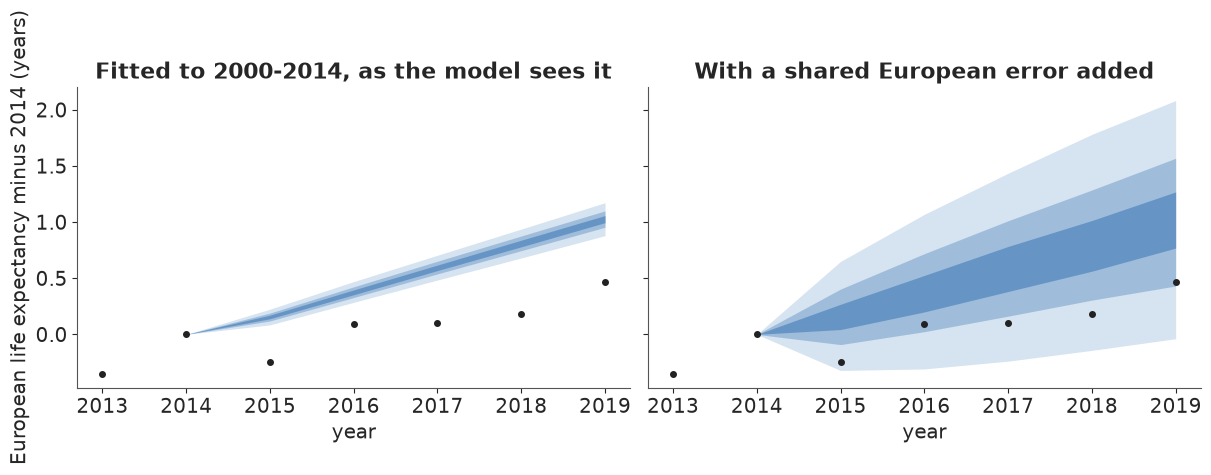

In [20]:
miss_h = (W19[:, None] * (obs_bt - med_bt)).sum(0)  # Europe's miss at horizons 1-5, pop-weighted
miss_plain = (obs_bt - med_bt).mean(0)                 # the plain average over countries
TAU = float(np.sqrt(np.mean(miss_h ** 2 / H5)))
print("Europe's miss by horizon (years):", miss_h.round(2), f"-> tau = {TAU:.2f} years a year")
var_own = (W19[None, :, None] * e0_bt).sum(1).var(0)  # the model's own European variance
tau_net = np.sqrt(np.mean(np.maximum(miss_h ** 2 - var_own, 0) / H5))
print(f"the model's own European sd by horizon: {np.sqrt(var_own).round(3)}; tau with that "
      f"variance taken out of the misses: {tau_net:.3f} (against {TAU:.3f})")
print("plain average over countries:", miss_plain.round(2),
      f"-> tau = {np.sqrt(np.mean(miss_plain ** 2 / H5)):.2f}")


def shared_error(S, H, rng_):
    """A European random-walk error in life expectancy, shared by every country: (S, 1, H)."""
    return TAU * np.cumsum(rng_.standard_normal((S, 1, H)), axis=-1)


e0_bt_cal = e0_bt + shared_error(e0_bt.shape[0], 5, np.random.default_rng(8))
lo_c, hi_c = np.quantile(e0_bt_cal, [0.05, 0.95], axis=0)
print("with the shared error added, the same fans cover "
      f"{((obs_bt >= lo_c) & (obs_bt <= hi_c)).mean():.0%} "
      "(a check on the fit we tuned it on, not a new test)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, arr, ttl in ((axes[0], e0_bt, "Fitted to 2000-2014, as the model sees it"),
                     (axes[1], e0_bt_cal, "With a shared European error added")):
    eu = (W19[None, :, None] * arr).sum(1)
    ref = (W19 * E0_OBS[:, YI[2014]]).sum()
    for lvl, al in [(0.9, 0.18), (0.6, 0.30), (0.3, 0.45)]:
        q_ = np.quantile(eu, [(1 - lvl) / 2, (1 + lvl) / 2], axis=0)
        ax.fill_between(np.r_[2014, BT], np.r_[0, q_[0] - ref], np.r_[0, q_[1] - ref], color=HI,
                        alpha=al, lw=0)
    yrs = np.arange(2013, 2020)
    ax.plot(yrs, (W19[:, None] * E0_OBS[:, [YI[y] for y in yrs]]).sum(0) - ref, "o", color=INK,
            ms=4)
    ax.set(title=ttl, xlabel="year")
axes[0].set_ylabel("European life expectancy minus 2014 (years)");

Europe's misses, weighted by population, were -0.40, -0.28, -0.49, -0.62 and -0.56 years at
horizons 1 to 5, which gives $\tau \approx 0.30$ years: after five years the shared error has a
standard deviation of about two thirds of a year. Part of each miss is the model's own European
uncertainty, already in the fan; it is small (an sd of 0.04-0.09 years) and taking it out moves
$\tau$ only in the third decimal. The plain average over countries, in which Malta counts as much
as Germany, would give 0.23; we use the weighted figure because every headline quotes the European
total. On the left of the figure the model's own fan for Europe is narrow, because averaging 30
independent countries cancels their noise, and the observed years sit far below it; on the right
they sit in the lower half of a much wider fan. That the widened fans cover 99% of the
country-years is no test, since $\tau$ came from these same misses, and $\tau$ rests on one
five-year episode. What the rough correction buys is the right order of magnitude: a five-year
forecast can be off by half a year or more for all of Europe at once.

This is also the notebook's main caveat, stated once here. The shared error is centred on zero,
but the one episode we have says the path errs on the optimistic side. If it did so again in
2020-2024, the gaps, the risk-equivalent ages and the count of extra deaths below are all too
large: each is more likely too high than too low.

## E · The path we were on, 2020-2024

### The counterfactual, draw by draw

Now the main fit, on 2000-2019, is run forward. For each of 1,000 posterior draws and each country
we continue $k$ from 2019 with that draw's drift and volatility, rebuild the 20 death rates for
2020-2024, and compute life expectancy $e_0^*$ with the same life table as for the data; adding
the shared error gives $e_0^* + \Delta$. The observed side allows for chance in small countries'
deaths: each draw uses rates $\text{Gamma}(D + \tfrac12, 1)/E$. The life expectancy lost is

$$ \text{LEL}_{ct} = e^*_{0,ct} + \Delta_t - e^{\text{obs}}_{0,ct}, $$

positive below the path, with a full posterior for every country and year. Europe's figure is the
average weighted by 2019 population. We also test the jump-off choice: starting the path from the
observed 2019 rates instead of the fitted ones.

In [21]:
S = 1000
k_star = project_k(P_main["k"][:, :, -1], P_main["drift"], P_main["sigma_k"], 5,
                   np.random.default_rng(9))
m_star = np.exp(P_main["a"][:, :, None, :] + P_main["b"][:, :, None, :] *
                k_star[..., None])  # S, C, 5, A
e0_star = e0_abridged(m_star)
DELTA = shared_error(S, 5, np.random.default_rng(10))
e0_cal = e0_star + DELTA


def shift_rates(m, e0_target):
    """Scale all rates of each schedule by one factor so that its life expectancy hits e0_target."""
    e0 = e0_abridged(m)
    slope = (e0_abridged(m * np.exp(0.01)) - e0) / 0.01  # d e0 / d log m, about -e0 times entropy
    s = (e0_target - e0) / slope
    s = s + (e0_target - e0_abridged(m * np.exp(s[..., None]))) / slope  # one Newton step
    return m * np.exp(s[..., None]).astype(m.dtype), s


M_CAL, s_cal = shift_rates(m_star, e0_cal)  # the path's rates with the shared error in them
print(f"the shared error as a common shift of every death rate: sd {np.std(s_cal[:, :, 0]):.1%} in "
      f"2020, {np.std(s_cal[:, :, 4]):.1%} in 2024; largest miss of the target after one Newton "
      f"step {np.abs(e0_abridged(M_CAL) - e0_cal).max():.3f} years")
Dh, Eh = D[:, [YI[y] for y in PROJ]], E[:, [YI[y] for y in PROJ]]
m_obs = np.random.default_rng(11).gamma(Dh[None] + 0.5, 1.0, size=(S,) + Dh.shape) / Eh[None]
e0_obs = e0_abridged(m_obs)  # observed life expectancy with Poisson noise in the deaths
LEL, LEL_CAL = e0_star - e0_obs, e0_cal - e0_obs
del m_obs

# Lee-Miller jump-off: anchor on the observed 2019 rates instead of the fitted ones
m19 = D[:, YI[2019]] / E[:, YI[2019]]
e0_jo = e0_abridged(m19[None, :, None, :] * np.exp(P_main["b"][:, :, None, :] *
                                                   (k_star - P_main["k"][:, :, -1:])[..., None]))
print(f"jump-off on observed 2019 rates moves the 2020 path by at most "
      f"{np.abs(np.median(e0_jo[:, :, 0], 0) - np.median(e0_star[:, :, 0], 0)).max():.2f} years")
LEL_JO_CAL = e0_jo + DELTA - e0_obs
del e0_jo


def q89(x):
    return np.median(x), np.quantile(x, 0.055), np.quantile(x, 0.945)


rows = []
for name, L in (("model alone", LEL), ("with shared error", LEL_CAL)):
    eu = (W19[None, :, None] * L).sum(1)
    for h, y in enumerate(PROJ):
        m_, l_, u_ = q89(eu[:, h])
        rows.append(dict(version=name, year=y, median=m_, lo89=l_, hi89=u_,
                         p_below=(eu[:, h] > 0).mean()))
EU_LEL = pd.DataFrame(rows)
print("Europe, population-weighted: years of life expectancy below the path")
print(EU_LEL.pivot(index="year", columns="version", values=["median", "lo89", "hi89", "p_below"])
      .round(2).to_string())

the shared error as a common shift of every death rate: sd 2.9% in 2020, 6.4% in 2024; largest miss of the target after one Newton step 0.002 years


jump-off on observed 2019 rates moves the 2020 path by at most 0.21 years
Europe, population-weighted: years of life expectancy below the path
             median                          lo89                          hi89                       p_below                  
version model alone with shared error model alone with shared error model alone with shared error model alone with shared error
year                                                                                                                           
2020           0.94              0.93        0.86              0.43        1.01              1.42         1.0              1.00
2021           1.29              1.28        1.19              0.63        1.40              1.93         1.0              1.00
2022           1.07              1.05        0.94              0.24        1.20              1.87         1.0              0.98
2023           0.57              0.58        0.43             -0.36        0.73          

Turned into death rates, the shared error is a common shift of every rate with a standard
deviation of 3% in 2020 and 6% in 2024. Starting from the observed 2019 rates moves a country's
2020 path by up to 0.21 years, not small next to the 2024 gaps; we keep the fitted start, which
treats 2019 as one noisy year like the others, and part F shows what the other choice does. For
Europe as a whole, life expectancy was 0.9 years below the path in 2020, **1.3 years below in
2021**, 1.1 in 2022, 0.6 in 2023 and **about half a year in 2024**. The shared error barely moves
the middle of these numbers but changes their intervals a great deal. For 2021 the 89% range
widens from 1.19-1.40 to 0.63-1.93 years, still far from zero. For 2024 it widens from 0.32-0.65
to -0.63 to 1.50, and the probability that Europe is still below its path drops from virtually
certain to 74%: *likely*, but no longer something the model alone can settle.

In [22]:
TAB = pd.DataFrame({"e0 2019": E0_OBS[:, YI[2019]], "e0 2021": E0_OBS[:, YI[2021]],
                    "e0 2024": E0_OBS[:, YI[2024]],
                    "lost 2020": np.median(LEL[:, :, 0], 0),
                    "lost 2021": np.median(LEL[:, :, 1], 0),
                    "lost 2024": np.median(LEL[:, :, 4], 0),
                    "P(lost) 2020": (LEL_CAL[:, :, 0] > 0).mean(0),
                    "P(lost) 2021": (LEL_CAL[:, :, 1] > 0).mean(0)}, index=GEOS)
TAB.index = [NAMES[g] for g in GEOS]
print(TAB.sort_values("lost 2021", ascending=False).round(2).to_string())
print("countries very likely below their path in 2021 (P > 0.9): model alone "
      f"{((LEL[:, :, 1] > 0).mean(0) > 0.9).sum()}, "
      f"with shared error {(TAB['P(lost) 2021'] > 0.9).sum()}")

             e0 2019  e0 2021  e0 2024  lost 2020  lost 2021  lost 2024  P(lost) 2020  P(lost) 2021
Bulgaria       74.78    71.11    75.78       1.82       4.16       0.05          1.00          1.00
Slovakia       77.72    74.61    78.46       0.93       3.50       0.31          0.99          1.00
Romania        75.51    72.70    76.46       1.85       3.50       0.40          1.00          1.00
Latvia         75.65    73.10    76.43       0.48       2.99       0.36          0.87          1.00
Poland         77.69    75.34    78.52       1.63       2.79       0.24          1.00          1.00
Lithuania      76.48    74.22    77.45       1.48       2.61      -0.08          1.00          1.00
Hungary        76.24    74.07    76.82       0.90       2.52       0.30          1.00          1.00
Czechia        79.11    77.19    80.11       1.16       2.33       0.06          1.00          1.00
Estonia        78.85    77.11    79.43       0.24       2.14       0.54          0.72          1.00


### East and west

The countries split in 2021. Bulgaria lost 4.2 years against its path, Romania and Slovakia 3.5,
Latvia 3.0, Poland 2.8, down to Estonia and Croatia 2.1: every formerly communist country except
Slovenia (1.3) lost two years or more. Outside the east, Greece (1.8) and Cyprus (1.3) lost most,
then the Netherlands 1.1, Austria and Italy 1.0, Spain 0.7, Belgium 0.5, and Sweden, Iceland and
Norway 0.2-0.3. Spain, Belgium and Italy lost more in 2020 than in 2021, the first wave having hit
them hardest; in the east 2021, the year of the Delta wave, when vaccination lagged, was far
worse. Norway was level with its path in 2020 (0.04 years above; below it *about as likely as
not*, 44%). The pattern matches what Schöley et al. (2022) found for 2021: a rebound in the west
and further losses in the east.

With the shared error, 22 of 30 countries were *very likely* (over 90%) below their path in 2021,
and every country at least *likely* (Iceland and Norway, 67-69%). The figure shows the model-alone
intervals for 2020, 2021 and 2024, ordered by the 2021 loss.

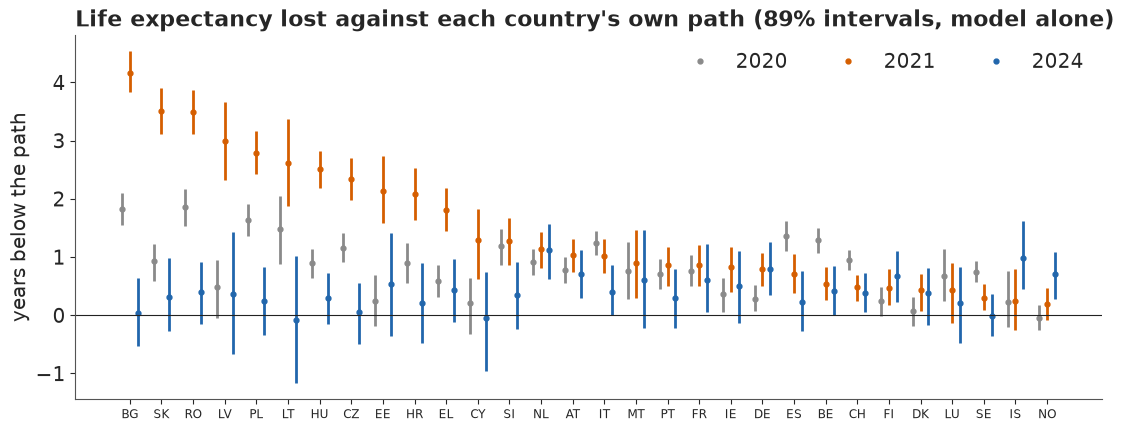

In [23]:
fig, ax = plt.subplots(figsize=(11, 4.2))
srt = np.argsort(-np.median(LEL[:, :, 1], 0))
for j, (h, col) in enumerate(((0, MUTED), (1, LO), (4, HI))):
    m_, l_, u_ = (np.median(LEL[:, :, h], 0), *np.quantile(LEL[:, :, h], [0.055, 0.945], axis=0))
    x = np.arange(C) + (j - 1) * 0.25
    ax.vlines(x, l_[srt], u_[srt], color=col, lw=2)
    ax.plot(x, m_[srt], "o", color=col, ms=3.5, label=str(PROJ[h]))
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(range(C), [GEOS[c] for c in srt], fontsize=8.5)
ax.set_ylabel("years below the path")
ax.legend(frameon=False, ncols=3)
ax.set_title("Life expectancy lost against each country's own path (89% intervals, model alone)",
             loc="left");

By 2024 the picture has turned over. The eastern countries with the deepest 2021 losses are now
among the closest to their paths (Bulgaria 0.05 years below, Lithuania slightly above), while the
Netherlands (1.1), Iceland (1.0), Germany (0.8), Norway (0.7), Austria (0.7) and Finland (0.7) are
the furthest below, with wider intervals than in 2021: five years of drift have accumulated.

## F · Has it come back?

### Bounce-back probabilities

Every count, label and tile from here on uses one number per country, the chance that it is still
below its path in 2024, $P(\text{LEL}_{c,2024} > 0)$, and one rule, the IPCC word for that chance
(the narrowest band, the lower one on a tie): over 66% is *likely* still below, under 33% *likely*
back, and in between we cannot tell. The test is lopsided: a country exactly back on its path
scores about 50%, so a full recovery shows up as "can't tell", and "likely back" needs a country
to be clearly *above* its path.

In [24]:
P_BELOW = (LEL[:, :, 4] > 0).mean(0)          # chance still below the path in 2024
P_BELOW_CAL = (LEL_CAL[:, :, 4] > 0).mean(0)  # the same with the shared error
WORD_BAND = {"likely": "below", "very likely": "below", "virtually certain": "below",
             "unlikely": "back", "very unlikely": "back", "exceptionally unlikely": "back",
             "about as likely as not": "can't tell"}


def band(p_below):
    """One rule for every count, label and tile: the IPCC word for the chance still below."""
    return np.array([WORD_BAND[pub.calibrated_word(p)] for p in np.atleast_1d(p_below)])


def bands(p_below):
    b = band(p_below)
    return {"likely still below (over 66%)": int((b == "below").sum()),
            "can't tell (33-66%)": int((b == "can't tell").sum()),
            "likely back (under 33% below)": int((b == "back").sum())}


def tile_pct(p):
    """A whole percent, or one decimal where rounding would land on a band edge."""
    s = f"{p:.0%}"
    return f"{p:.1%}" if s in ("33%", "66%") else s


BAND = band(P_BELOW_CAL)
N_BELOW, N_BACK = int((BAND == "below").sum()), int((BAND == "back").sum())
N_CANT = C - N_BACK - N_BELOW
print("2024, chance still below the path; model alone:", bands(P_BELOW))
print("2024, with shared error:", bands(P_BELOW_CAL))
cant = BAND == "can't tell"
print(f"can't tell: chance still below {P_BELOW_CAL[cant].min():.1%}-"
      f"{P_BELOW_CAL[cant].max():.1%}; likely below: from {P_BELOW_CAL[~cant].min():.1%}")
print("on the line:", {NAMES[GEOS[c]]: round(float(P_BELOW_CAL[c]), 3) for c in range(C)
                       if 0.64 <= P_BELOW_CAL[c] <= 0.68})
print("closest to back (model alone, with shared error):",
      {NAMES[GEOS[c]]: (round(P_BELOW[c], 2), round(P_BELOW_CAL[c], 2))
       for c in np.argsort(P_BELOW_CAL)[:6]})
print("furthest:", {NAMES[GEOS[c]]: (round(P_BELOW[c], 2), round(P_BELOW_CAL[c], 2))
                    for c in np.argsort(-P_BELOW_CAL)[:6]})
eu_jo = (W19[None, :, None] * LEL_JO_CAL).sum(1)
print("jump-off on observed 2019 rates instead:", bands((LEL_JO_CAL[:, :, 4] > 0).mean(0)),
      f"; Europe 2024 {np.median(eu_jo[:, 4]):.2f} years below, chance "
      f"{(eu_jo[:, 4] > 0).mean():.0%}; countries changing band:",
      [NAMES[GEOS[c]] for c in np.flatnonzero(band((LEL_JO_CAL[:, :, 4] > 0).mean(0)) != BAND)])
# Germany's 2023 break (Zensus 2022), left as published: put the years before it on the census
# level at ages 60+ (migration in 2022 hides the step at younger ages) and redo the 2024 gap
cD = GEOS.index("DE")
for adj in (False, True):
    r23 = break_ratio("DE", 2023, adjust=adj)[0]
    r23 = np.where(np.arange(A) >= LABELS.index("60-64"), r23, 1.0)
    e0_de = e0_abridged(m_star[:, cD, 4] / r23) + DELTA[:, 0, 4]  # path rates rise by 1/r
    lel_de = e0_de - e0_obs[:, cD, 4]
    step_old = np.average(r23[13:19], weights=D[cD, YI[2023], 13:19]) - 1
    print(f"Germany 2024 with the 2023 step at 60+ corrected "
          f"({'deaths added back' if adj else 'raw'}; step at 60-89 {step_old:+.1%}): "
          f"{np.median(lel_de):.2f} years below (was {np.median(LEL_CAL[:, cD, 4]):.2f}), chance "
          f"{(lel_de > 0).mean():.0%} (was {P_BELOW_CAL[cD]:.0%})")
nordic = [GEOS.index(g) for g in ("NO", "IS", "FI", "SE", "DK")]
print("Nordic countries, years below the path 2020-2024 (median):")
print(pd.DataFrame(np.median(LEL[:, nordic], 0), index=[NAMES[GEOS[c]] for c in nordic],
                   columns=PROJ).round(2).to_string())

2024, chance still below the path; model alone: {'likely still below (over 66%)': 25, "can't tell (33-66%)": 5, 'likely back (under 33% below)': 0}
2024, with shared error: {'likely still below (over 66%)': 17, "can't tell (33-66%)": 13, 'likely back (under 33% below)': 0}
can't tell: chance still below 44.6%-65.2%; likely below: from 66.3%
on the line: {'Denmark': 0.665, 'Hungary': 0.642, 'Portugal': 0.65, 'Slovenia': 0.663, 'Slovakia': 0.652}
closest to back (model alone, with shared error): {'Cyprus': (np.float64(0.47), np.float64(0.45)), 'Lithuania': (np.float64(0.46), np.float64(0.47)), 'Sweden': (np.float64(0.48), np.float64(0.49)), 'Bulgaria': (np.float64(0.56), np.float64(0.51)), 'Czechia': (np.float64(0.58), np.float64(0.51)), 'Luxembourg': (np.float64(0.69), np.float64(0.57))}
furthest: {'Netherlands': (np.float64(1.0), np.float64(0.93)), 'Iceland': (np.float64(1.0), np.float64(0.89)), 'Germany': (np.float64(1.0), np.float64(0.85)), 'Austria': (np.float64(0.99), np.float64(0.

With the shared error, 17 countries are *likely* still below their path in 2024, and for the other
13 we cannot tell: their chances of still being below run from 45% to 65%, which fits both a full
recovery and a small remaining gap. None is likely back. On the model alone 25 are likely below;
the other five (Cyprus, Lithuania, Sweden, Bulgaria, Czechia) are 46-58% below, and 45-51% with
the shared error, because their middle values were already near zero. The furthest are the
Netherlands (*very likely* still below, 93%), Iceland, Germany, Austria, Norway and Finland
(*likely*, 81-89%).

A rule with edges sorts the countries near them by luck. Denmark (66.5%) and Slovenia (66.3%) are
just over the line, Portugal and Slovakia (65%) just under it, and with 1,000 draws a probability
carries a Monte Carlo error of 1.5 points or more. The jump-off matters at the same scale:
starting from the observed 2019 rates gives 18 likely below and 12 undecided, moving five
countries across the line (Greece, Spain, Portugal, Romania, Slovakia), while Europe's 2024 gap
barely changes (0.53 years, 76%). The split of the middle countries is soft; the broad picture is
not. Germany's uncorrected 2023 break, put on the census level at 60+, moves its 2024 gap from
0.78 to about 0.7 years and its chance of still being below from 85% to 82-84%.

The Nordic rows show a late pandemic. Norway, Iceland and Finland lost at most half a year in
2020-2021 (Norway nothing in 2020), then 1.0-1.3 years in 2022, as Omicron spread after
restrictions were lifted, and were still 0.7-1.0 years below in 2024. Sweden, with its early,
much-debated 2020 losses (0.75), is the one Nordic country we cannot call (49% still below);
Denmark sits on the line. The figure puts 2021 and 2024 side by side for every country, ordered by
the chance of still being below.

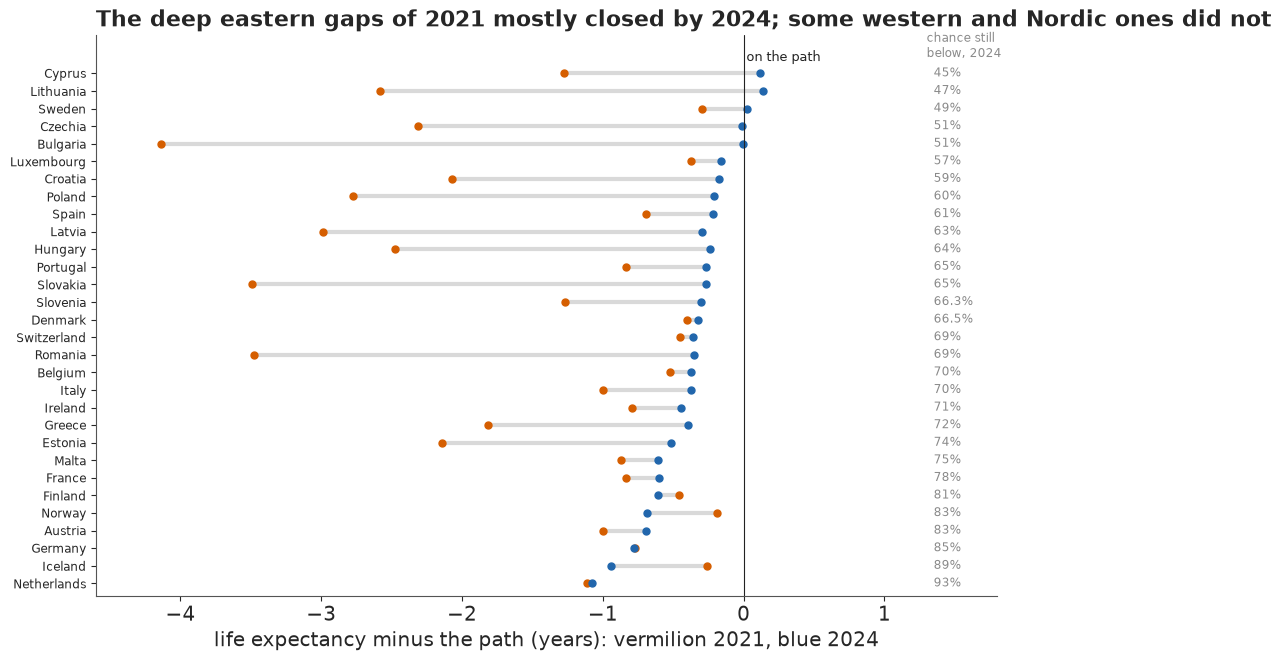

In [25]:
fig, ax = plt.subplots(figsize=(10, 6.5))
srt = np.argsort(-P_BELOW_CAL)
for i, c in enumerate(srt):
    l21, l24 = np.median(LEL_CAL[:, c, 1]), np.median(LEL_CAL[:, c, 4])
    ax.plot([-l21, -l24], [i, i], color=LIGHT, lw=3, zorder=1)
    ax.plot(-l21, i, "o", color=LO, ms=5, zorder=2)
    ax.plot(-l24, i, "o", color=HI, ms=5, zorder=2)
    ax.text(1.35, i, tile_pct(P_BELOW_CAL[c]), va="center", fontsize=8.5, color=MUTED)
ax.axvline(0, color=INK, lw=0.8)
ax.text(0.02, C - 0.3, "on the path", fontsize=9, color=INK)
ax.text(1.3, C - 0.3, "chance still\nbelow, 2024", fontsize=8.5, color=MUTED, va="bottom")
ax.set_yticks(range(C), [NAMES[GEOS[c]] for c in srt], fontsize=8.5)
ax.set_xlim(-4.6, 1.8)
ax.set_ylim(-0.7, C + 1.2)
ax.set_xlabel("life expectancy minus the path (years): vermilion 2021, blue 2024")
ax.set_title("The deep eastern gaps of 2021 mostly closed by 2024; some western and Nordic ones "
             "did not", loc="left");

Most rows run left to right, a large 2021 gap (vermilion) closing towards zero by 2024 (blue); a
few run the other way. Norway, Iceland and Finland were further below their paths in 2024 than in
2021, and the Netherlands and Germany did not move at all. Close to their paths in 2024 are
countries that lost little (Sweden) and countries whose losses were so concentrated in 2021 that
the rebound brought them back to even odds (Bulgaria, Lithuania). When a pandemic kills many frail
older people the survivors are on average healthier, so some of such a rebound can be selection
rather than a return to the old trend; the model cannot separate the two.

### Poisson against negative binomial

Does the likelihood matter? We refit the pooled model with Poisson counts, whose only noise is the
luck of who dies.

In [26]:
m_po, init_po, _ = lee_carter_model(D[:, fit_years], E[:, fit_years], GEOS, YEARS[fit_years],
                                    lik="pois")
id_po = fit(m_po, init_po, draws=500, label="pooled Poisson 2000-2019")
check(id_po, ["b", "k", "drift", "sigma_k", "beta_eu"], m_po)
P_po = thin(id_po, ["a", "b", "k", "drift", "sigma_k"], 1000, np.random.default_rng(12))
cov_po, size_po, m_fit = ppc_coverage(P_po, "pois", np.random.default_rng(13))
del m_fit, id_po, m_po
sk_nb, sk_po = P_main["sigma_k"].mean(0), P_po["sigma_k"].mean(0)
print(f"90% predictive intervals of deaths cover {cov_po:.1%} of cells under Poisson "
      f"({cov_nb:.1%} under NB); by expected deaths: {size_po}")
print(f"sigma_k, Poisson / NB: median ratio {np.median(sk_po / sk_nb):.2f} "
      f"(e.g. Spain {sk_nb[cE]:.2f} -> {sk_po[cE]:.2f})")
k_po = project_k(P_po["k"][:, :, -1], P_po["drift"], P_po["sigma_k"], 5, np.random.default_rng(14))
e0_po = e0_abridged(np.exp(P_po["a"][:, :, None, :] + P_po["b"][:, :, None, :] * k_po[..., None]))
w90 = lambda x: (np.quantile(x[:, :, 4], 0.95, 0) - np.quantile(x[:, :, 4], 0.05, 0)).mean()
LEL_PO = e0_po - e0_obs
print(f"mean width of the 90% fan in 2024: NB {w90(e0_star):.2f}, Poisson {w90(e0_po):.2f} years")
eu_po = (W19[None, :, None] * LEL_PO).sum(1)
print("Poisson, Europe below the path: 2021 %.2f (%.2f, %.2f), 2024 %.2f (%.2f, %.2f)"
      % (*q89(eu_po[:, 1]), *q89(eu_po[:, 4])), "; countries likely back in 2024:",
      int((band((LEL_PO[:, :, 4] > 0).mean(0)) == "back").sum()))
del P_po, k_po, e0_po

[pooled Poisson 2000-2019] 21 s; 400 tuning steps, 500 draws x 4 chains; divergences 0; tree depth 5-9


                    values  max r_hat  min ESS (bulk)
b                    600.0      1.010         983.026
k                    600.0      1.008        1118.977
drift                 30.0      1.004        1631.450
sigma_k               30.0      1.014         559.084
beta_eu               20.0      1.003        1238.017
ALL free variables  1864.0      1.014         609.259


90% predictive intervals of deaths cover 73.6% of cells under Poisson (92.6% under NB); by expected deaths: {'0-10': (0.03, 0.956), '10-1000': (0.48, 0.854), '1000-inf': (0.49, 0.607)}
sigma_k, Poisson / NB: median ratio 1.56 (e.g. Spain 0.42 -> 0.81)
mean width of the 90% fan in 2024: NB 1.18, Poisson 1.65 years
Poisson, Europe below the path: 2021 1.37 (1.19, 1.53), 2024 0.58 (0.31, 0.84) ; countries likely back in 2024: 0


The Poisson fit has no divergences but trees of depth up to 9, against 5 for the negative
binomial. Its 90% predictive intervals cover only 74% of cells, and 61% of those with over 1,000
deaths. The extra variation goes into the period index. Year-to-year $\sigma_k$ is about 1.5 times
larger under Poisson (Spain 0.42 to 0.81), so a bad flu winter reads as a move of the trend, and
the 90% fans in 2024 are 1.65 years wide on average instead of 1.18. The headline answers barely
change (Europe 1.4 years below in 2021, 0.6 in 2024, no country likely back), but a Poisson model
is too confident in each cell and too vague about the trend.

## G · Explaining it to everyone

### The statistician's plot

A statistician summarising part F would draw a forest plot: each country's 2024 loss, a point and
an 89% interval (the level used in every table here), sorted.

89% interval clear of zero: []
chance still below in 2024, top 8: {'Netherlands': np.float64(0.93), 'Iceland': np.float64(0.89), 'Germany': np.float64(0.85), 'Austria': np.float64(0.83), 'Norway': np.float64(0.83), 'Finland': np.float64(0.81), 'France': np.float64(0.78), 'Malta': np.float64(0.75)}


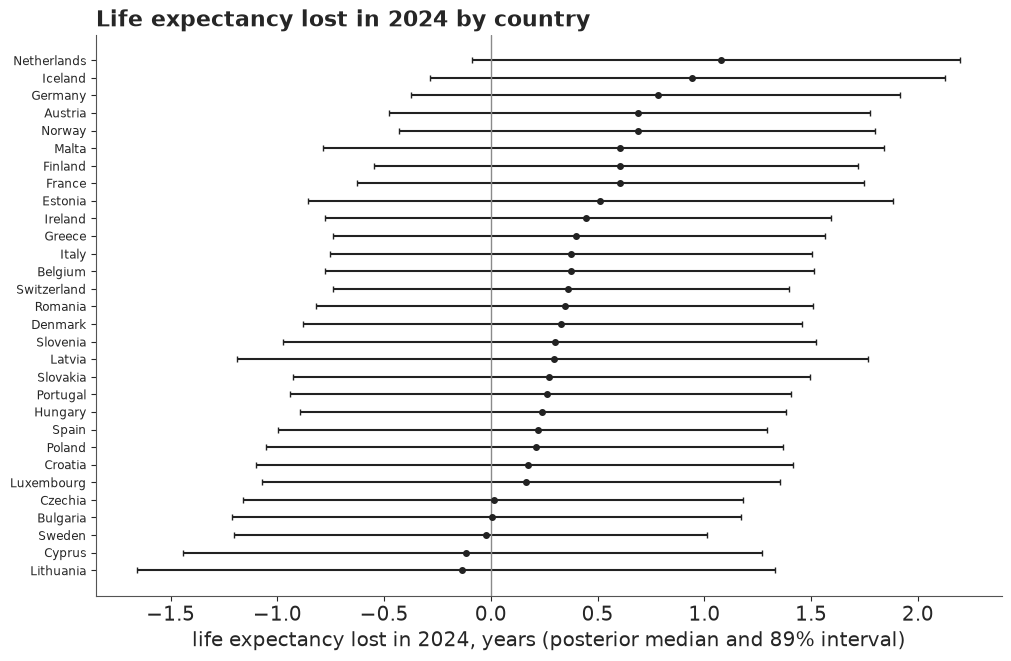

In [27]:
fig, ax = plt.subplots(figsize=(10, 6.5))
srt = np.argsort(np.median(LEL_CAL[:, :, 4], 0))
m_ = np.median(LEL_CAL[:, :, 4], 0)
l_, u_ = np.quantile(LEL_CAL[:, :, 4], [0.055, 0.945], axis=0)
ax.errorbar(m_[srt], range(C), xerr=[m_[srt] - l_[srt], u_[srt] - m_[srt]], fmt="o", color=INK,
            ms=4, capsize=2)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(C), [NAMES[GEOS[c]] for c in srt], fontsize=8.5)
ax.set_xlabel("life expectancy lost in 2024, years (posterior median and 89% interval)")
ax.set_title("Life expectancy lost in 2024 by country", loc="left")
print("89% interval clear of zero:", [NAMES[GEOS[c]] for c in range(C) if l_[c] > 0 or u_[c] < 0])
print("chance still below in 2024, top 8:",
      {NAMES[GEOS[c]]: round(P_BELOW_CAL[c], 2) for c in np.argsort(-P_BELOW_CAL)[:8]});

For a reader who knows what a posterior interval is, this is the right figure. Every 89% interval
crosses zero, yet the Netherlands is *very likely* (93%) still below its path. For anyone else it
has three problems. The interval ends look like limits, and readers judge a value just inside a
bar as much more likely than one just outside (Correll & Gleicher 2014, "Error bars considered
harmful"). The plot has no time in it, so the question the public asks - "where were we heading,
and where are we?" - is answered only by implication. And it shows "life expectancy lost", a
quantity that exists only inside a model, without the model's path.

### The path we were on, country by country

The headline display is a **graded fan chart**: the counterfactual path as nested 30/60/90% bands
that fade outward, beside the dots of what happened. The Bank of England has drawn its inflation
forecasts this way since the 1990s (Britton, Fisher & Whitley 1998), and Spiegelhalter, Pearson &
Short (2011) discuss it among displays of uncertainty about the future. Its known pitfall is that
readers take the darkest band as "what would have happened"; so one tile, Sweden's, states in
words what the whole fan means ("9 in 10 chance the path lies in the shaded fan"), and the fan has
no outline, which would bring back the cliff.

Thirty small fans are arranged as a **tile-grid map**: each country is a tile placed roughly where
it lies in Europe, so the east-west contrast is visible as geography. Every tile shares one scale
relative to its own 2019 level (the grey line), and the fans include the shared error. The
vermilion bar and the first number under each tile give the 2021 gap. A fan is too small to show
whether a 2024 dot sits a little above or below its middle, so the second label says it in words:
the chance the country was still below its path in 2024, banded by the rule of part F.

Nearly all of Europe fell below the path it was on. By 2024, 17 of 30 countries were likely still below it; for the other 13 we cannot tell
tile labels: {'below': 17, "can't tell": 13, 'back': 0}


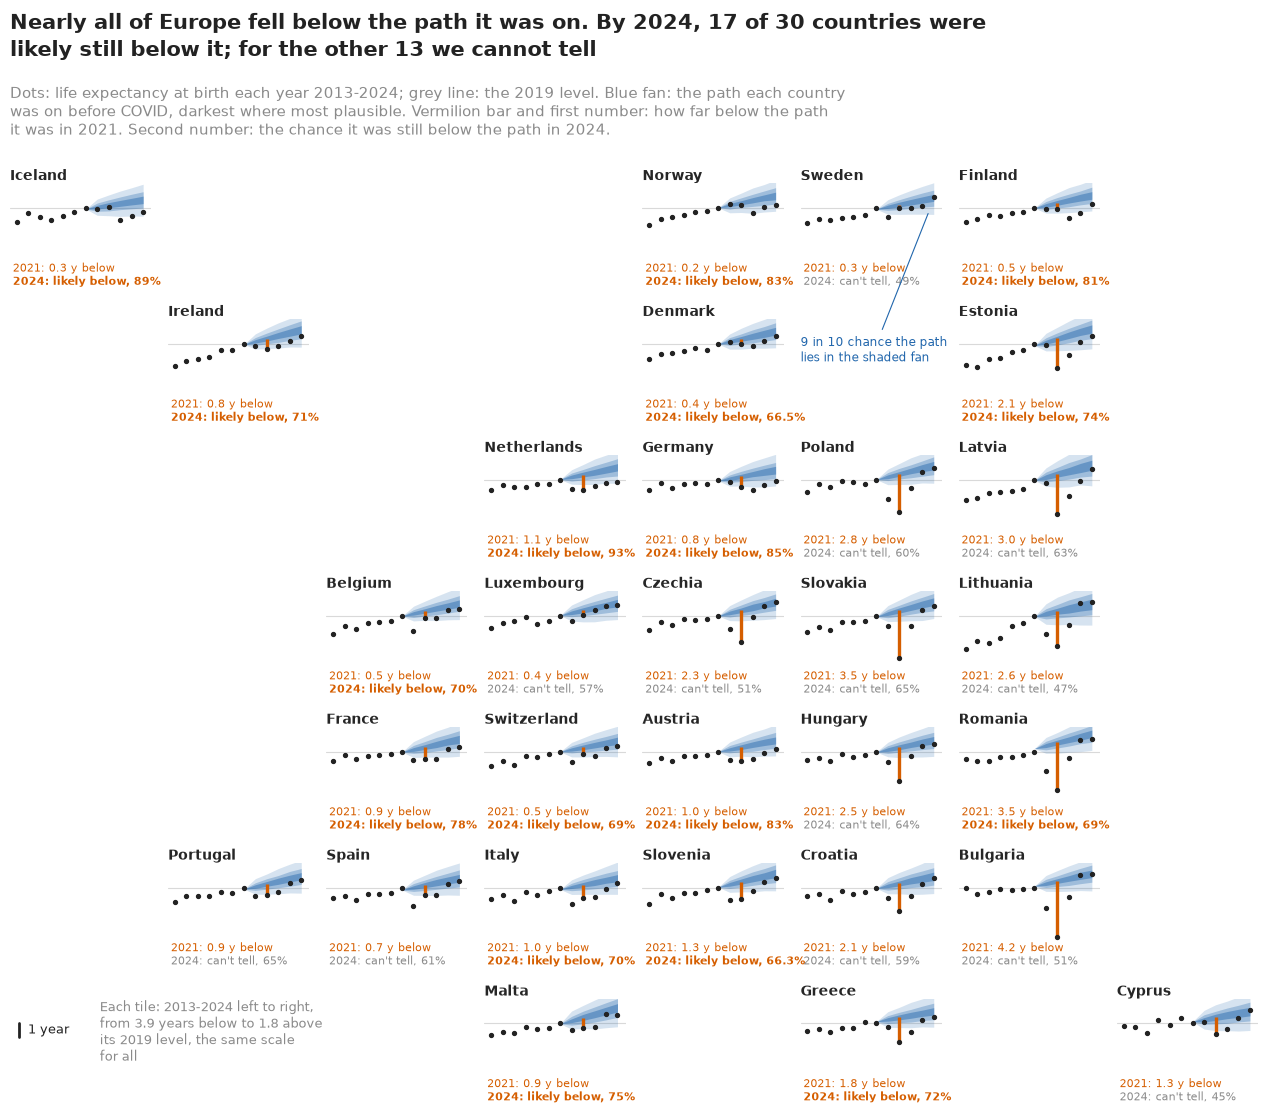

In [28]:
TILE = {"IS": (0, 0), "NO": (0, 4), "SE": (0, 5), "FI": (0, 6),
        "IE": (1, 1), "DK": (1, 4), "EE": (1, 6),
        "NL": (2, 3), "DE": (2, 4), "PL": (2, 5), "LV": (2, 6),
        "BE": (3, 2), "LU": (3, 3), "CZ": (3, 4), "SK": (3, 5), "LT": (3, 6),
        "FR": (4, 2), "CH": (4, 3), "AT": (4, 4), "HU": (4, 5), "RO": (4, 6),
        "PT": (5, 1), "ES": (5, 2), "IT": (5, 3), "SI": (5, 4), "HR": (5, 5), "BG": (5, 6),
        "MT": (6, 3), "EL": (6, 5), "CY": (6, 7)}
X0 = 2013


YLIM = (-3.9, 1.8)


def fan_tile(ax, c, arr, annotate=False):
    ref = E0_OBS[c, YI[2019]]
    xs = np.r_[2019, PROJ]
    for lvl, al in [(0.9, 0.18), (0.6, 0.30), (0.3, 0.45)]:
        q_ = np.quantile(arr[:, c], [(1 - lvl) / 2, (1 + lvl) / 2], axis=0) - ref
        start = E0_FIT19[c] - ref  # the path starts from the fitted 2019 value
        ax.fill_between(xs, np.r_[start, q_[0]], np.r_[start, q_[1]], color=HI, alpha=al, lw=0)
    yrs = np.arange(X0, 2025)
    y = E0_OBS[c, [YI[t] for t in yrs]] - ref
    ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
    med21 = np.median(arr[:, c, 1]) - ref
    gap21 = np.median(LEL[:, c, 1])  # the model-alone median gap, as in the tables
    ax.plot([2021, 2021], [y[2021 - X0], med21], color=LO, lw=2.4, solid_capstyle="butt")
    ax.plot(yrs, y, "o", ms=2.8, color=INK, zorder=3)
    ax.set_ylim(*YLIM)
    ax.set_xlim(X0 - 0.6, 2024.7)
    ax.set_xticks([])
    ax.set_yticks([])
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_title(NAMES[GEOS[c]], fontsize=10, loc="left", pad=1)
    word, col = {"below": ("likely below", LO), "back": ("likely back", HI),
                 "can't tell": ("can't tell", MUTED)}[BAND[c]]
    ax.text(0.02, -0.02, f"2021: {gap21:.1f} y below", transform=ax.transAxes, fontsize=8,
            color=LO, va="top")
    ax.text(0.02, -0.19, f"2024: {word}, {tile_pct(P_BELOW_CAL[c])}", transform=ax.transAxes,
            fontsize=8, color=col, va="top", weight="normal" if BAND[c] == "can't tell" else "bold")
    if annotate:  # the explanation sits in the empty cell below the tile
        ax.annotate("9 in 10 chance the path\nlies in the shaded fan",
                    xy=(2023.6, np.quantile(arr[:, c, 3], 0.1) - ref), xytext=(0.0, -0.95),
                    textcoords="axes fraction", fontsize=8.5, color=HI, va="top", ha="left",
                    arrowprops=dict(arrowstyle="-", color=HI, lw=0.8))


HEAD_TITLE = ("Nearly all of Europe fell below the path it was on. By 2024, "
              f"{N_BELOW} of 30 countries were\nlikely still below it"
              + (f", {N_BACK} likely back" if N_BACK else "")
              + f"; for the other {N_CANT} we cannot tell")
def headline_figure():
    """The tile-grid map, drawn fresh for each display (a second render misplaces the tiles)."""
    fig = plt.figure(figsize=(13, 11.6), layout="none")
    fig.text(0.03, 0.98, HEAD_TITLE, fontsize=15, color=INK, va="top", weight="bold",
             linespacing=1.3)
    fig.text(0.03, 0.915, "Dots: life expectancy at birth each year 2013-2024; grey line: the 2019 "
             "level. Blue fan: the path each country\nwas on before COVID, darkest where most "
             "plausible. Vermilion bar and first number: how far below the path\nit was in 2021. "
             "Second number: the chance it was still below the path in 2024.",
             fontsize=11, color=MUTED, va="top")
    gs = fig.add_gridspec(7, 8, left=0.03, right=0.99, bottom=0.06, top=0.83, hspace=0.75,
                          wspace=0.12)
    for g, (r, cc) in TILE.items():
        fan_tile(fig.add_subplot(gs[r, cc]), GEOS.index(g), e0_cal, annotate=(g == "SE"))
    ax = fig.add_subplot(gs[6, 0:2])
    ax.set_ylim(*YLIM)
    ax.set_xlim(0, 1)
    ax.axis("off")
    ax.plot([0.03, 0.03], [-1, 0], color=INK, lw=2)
    ax.text(0.06, -0.5, "1 year", va="center", fontsize=9, color=INK)
    ax.text(0.3, YLIM[1], "Each tile: 2013-2024 left to right,\nfrom 3.9 years below to 1.8 above\n"
            "its 2019 level, the same scale\nfor all", fontsize=9, color=MUTED, va="top")
    return fig


fig_top = headline_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
fig_head = headline_figure()
print(HEAD_TITLE.replace("\n", " "))
print("tile labels:", {w: int((BAND == w).sum()) for w in ("below", "can't tell", "back")})

The map makes the main point before anyone reads a number: the long vermilion bars are all on the
eastern edge, from Estonia to Bulgaria, and the western and northern tiles show shallow dips. By
2024 most dots sit in the lower part of their fans, the Netherlands' at the bottom edge. The
second line of labels carries the 2024 finding: "likely below" across most of the north and west,
"can't tell" through much of the east, where the deep 2021 losses rebounded, and in Luxembourg,
Spain, Portugal and Sweden. Denmark's and Slovenia's labels carry a decimal, so that "likely"
never sits beside a bare 66%.

The plain-words block states its probabilities with `pub.how_sure`, which pins each word to the
IPCC scale (Mastrandrea et al. 2010) and prints the number with it, since readers interpret the
words alone very differently (Budescu, Broomell & Por 2009); the confidence statement is our trust
in the model.

In [29]:
eu_cal = (W19[None, :, None] * LEL_CAL).sum(1)
print(pub.how_sure((eu_cal[:, 4] > 0).mean(), "Europe as a whole was still below its path in 2024",
                   "low", "the same method, tested on 2015-2019, was off by about half a year "
                   "after five years, with no pandemic at all"))
print(pub.how_sure((eu_cal[:, 1] > 0).mean(), "Europe was below its path in 2021", "high",
                   "the 2021 gap is several times the forecast's own error"))
print(f"Europe 2021: {np.median(eu_cal[:, 1]):.2f} years ({np.quantile(eu_cal[:, 1], 0.055):.2f}-"
      f"{np.quantile(eu_cal[:, 1], 0.945):.2f}); 2024: {np.median(eu_cal[:, 4]):.2f} "
      f"({np.quantile(eu_cal[:, 4], 0.055):.2f} to {np.quantile(eu_cal[:, 4], 0.945):.2f})")

It is *likely* (74%) that Europe as a whole was still below its path in 2024. We have *low confidence* in that figure: the same method, tested on 2015-2019, was off by about half a year after five years, with no pandemic at all.
It is *virtually certain* (>99%) that Europe was below its path in 2021. We have *high confidence* in that figure: the 2021 gap is several times the forecast's own error.
Europe 2021: 1.28 years (0.63-1.93); 2024: 0.48 (-0.63 to 1.50)


### What it meant for one person

"1.3 years of life expectancy" describes a population. A personal translation is the
**risk-equivalent age**: in 2020, the death rate a 60-64-year-old in Spain actually faced equalled
the rate the path would have given someone of what age? For each posterior draw we take the
observed rate at 60-64 (with Poisson noise) and find, by interpolating the counterfactual log
rates between age-group midpoints (from 40-44 up, where rates rise with age), the age with the
same expected risk. The path's rates include the shared error: each draw of $\Delta$ becomes one
proportional shift $e^{s}$ of every rate that moves the path's life expectancy by $\Delta$ (one
Newton step; $s \approx -\Delta / (e_0 H)$, with $H$ the life table's entropy). Each card is a
**quantile dotplot**: 20 dots, each a 1-in-20 chance, from which readers estimate probabilities
less variably than from densities (Kay, Kola, Hullman & Munson 2016) and decide better (Fernandes
et al. 2018). There is no mean line, which makes readers ignore the spread (Kale, Kay & Hullman
2021). The dashed line is the person's real age, 62.5.

risk-equivalent age at 60-64, years older (median and 89%); 2020 width of the 89% range: as drawn / model alone / deaths' chance alone
  Spain     2020 +1.6 (+0.9, +2.3)   2021 +1.4 (+0.4, +2.3);  2020 chance above zero 100%;  widths 1.4 / 0.7 / 0.3
  Italy     2020 +1.4 (+0.8, +2.0)   2021 +1.4 (+0.6, +2.2);  2020 chance above zero 100%;  widths 1.3 / 0.6 / 0.2
  Poland    2020 +1.7 (+1.0, +2.3)   2021 +3.2 (+2.2, +4.0);  2020 chance above zero 100%;  widths 1.4 / 0.6 / 0.2


  Bulgaria  2020 +3.1 (+2.3, +3.8)   2021 +5.9 (+5.0, +6.7);  2020 chance above zero 100%;  widths 1.5 / 0.8 / 0.4


  Germany   2020 +0.3 (-0.3, +0.9)   2021 +1.0 (+0.1, +1.9);  2020 chance above zero 75%;  widths 1.2 / 0.6 / 0.2
  Sweden    2020 +0.3 (-0.3, +0.9)   2021 +0.3 (-0.5, +1.1);  2020 chance above zero 76%;  widths 1.3 / 0.7 / 0.5


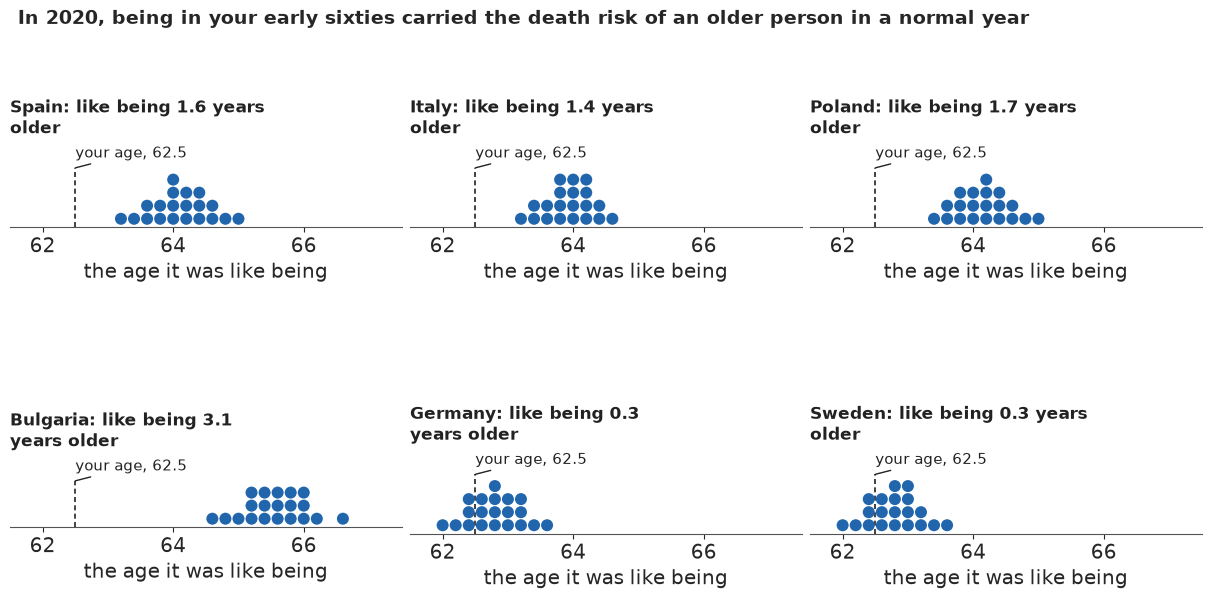

In [30]:
# risk-equivalent age: the age whose counterfactual death rate equals the observed rate at 60-64
g60 = LABELS.index("60-64")
rq = np.random.default_rng(15)
CARDS = ["ES", "IT", "PL", "BG", "DE", "SE"]
a40 = LABELS.index("40-44")  # rates rise with age from here on, so interpolation is safe
assert np.all(np.diff(np.log(M_CAL[:, :, :2, a40:]), axis=-1) > 0)


def risk_age(m_path, c, h, noise=True):
    """Years older than 62.5 whose path death rate equals the observed rate at 60-64: (S,)."""
    d, e = D[c, YI[2020 + h], g60], E[c, YI[2020 + h], g60]
    mo = rq.gamma(d + 0.5, 1.0, S) / e if noise else np.full(S, d / e)
    lm = np.log(m_path[:, c, h, a40:])
    return np.array([np.interp(np.log(mo[s]), lm[s], MID[a40:]) for s in range(S)]) - MID[g60]


REQ = {g: [risk_age(M_CAL, GEOS.index(g), h) for h in (0, 1)] for g in CARDS}
w89 = lambda x: np.quantile(x, 0.945) - np.quantile(x, 0.055)
print("risk-equivalent age at 60-64, years older (median and 89%); 2020 width of the 89% range: "
      "as drawn / model alone / deaths' chance alone")
for g in CARDS:
    c = GEOS.index(g)
    r0, r1 = q89(REQ[g][0]), q89(REQ[g][1])
    alone = risk_age(m_star, c, 0)
    chance = risk_age(np.median(M_CAL, 0, keepdims=True).repeat(S, 0), c, 0)
    print(f"  {NAMES[g]:9s} 2020 {r0[0]:+.1f} ({r0[1]:+.1f}, {r0[2]:+.1f})   "
          f"2021 {r1[0]:+.1f} ({r1[1]:+.1f}, {r1[2]:+.1f});  2020 chance above zero "
          f"{(REQ[g][0] > 0).mean():.0%};  widths {w89(REQ[g][0]):.1f} / {w89(alone):.1f} / "
          f"{w89(chance):.1f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, g in zip(axes.ravel(), CARDS):
    x = MID[g60] + REQ[g][0]
    pub.quantile_dotplot(ax, x, n=20, xlim=(61.5, 67.5), bins=30,
                         xlabel="the age it was like being",
                         title=f"{NAMES[g]}: like being {np.median(REQ[g][0]):.1f} years older",
                         you_are_here=MID[g60], here_label="your age, 62.5")
    for ln in ax.lines:  # the reference line goes behind the dots
        ln.set_zorder(0.5)
    ax.set_xticks([62, 64, 66])
fig.suptitle("In 2020, being in your early sixties carried the death risk of an older person in a "
             "normal year", x=0.01, ha="left", fontsize=13.5);

In 2020, being in your early sixties in Spain carried the risk of death of someone about 1.6 years
older in a normal year (89%: 0.9-2.3); in Italy 1.4, in Poland 1.7, in Bulgaria 3.1. In Germany
and Sweden the shift was about 0.3 years (-0.3 to +0.9): *likely* above zero (75-76%). In 2021 the
eastern figures roughly doubled: Bulgaria 5.9 years, Poland 3.2. Each card's 89% range is 1.2-1.5
years wide; on the model alone it would be about half that (0.6-0.8), and the chance in a year's
deaths at 60-64 alone gives 0.2-0.5. The spread is mostly the path's uncertainty, and like every
loss here the shifts are more likely too large than too small (part D).

### A hundred possible counts of extra deaths

Life expectancy is a rate; the other number people ask for is a count. Excess deaths are observed
deaths minus the deaths the path implies for each year's real population, $\sum D - \sum E\, m^*$,
summed over 2020-2024 and the 30 countries, with the shared error in the path's rates as for the
cards. We show 100 equally spaced quantiles of its posterior as 100 dots, one per simulated world,
the "ballswarm" FiveThirtyEight used for its 2020 election forecast: the reader counts dots rather
than reading an interval.

excess deaths 2020-2024, 30 countries, with the shared error: 2.04 million (0.30-3.48)
excess deaths 2020-2024, 30 countries, model alone: 2.05 million (1.83-2.28)
excess deaths 2020-2024, 30 countries, if the 2015-2019 shortfall repeated: 0.94 million (-0.90-2.45)
by year (thousands, median and 89%): {2020: (499, 260, 714), 2021: (627, 324, 914), 2022: (523, 140, 881), 2023: (232, -223, 612), 2024: (160, -377, 597)}


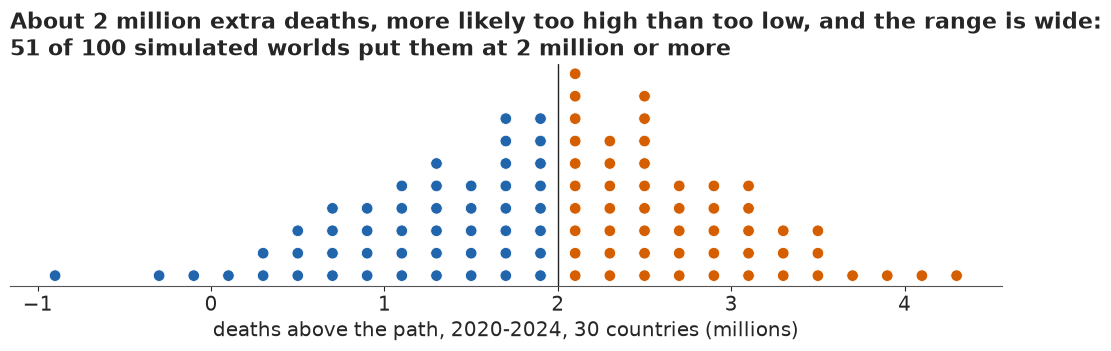

In [31]:
def excess(m):
    """Observed minus expected deaths on the observed exposures: (S, C, 5)."""
    return Dh.sum(-1)[None] - (Eh[None] * m).sum(-1)


EXCESS_ALONE = excess(m_star).sum((1, 2))
by_year = excess(M_CAL).sum(1)
EXCESS = by_year.sum(1)
# the same, if the path's 2015-2019 shortfall in Europe repeated instead of averaging zero
EXCESS_SLOW = excess(shift_rates(m_star, e0_cal + miss_h[None, None, :])[0]).sum((1, 2))
for name, x in (("with the shared error", EXCESS), ("model alone", EXCESS_ALONE),
                ("if the 2015-2019 shortfall repeated", EXCESS_SLOW)):
    print(f"excess deaths 2020-2024, 30 countries, {name}: %.2f million (%.2f-%.2f)"
          % tuple(v / 1e6 for v in q89(x)))
print("by year (thousands, median and 89%):",
      {int(y): tuple(round(v / 1e3) for v in q89(by_year[:, h])) for h, y in enumerate(PROJ)})
q100 = np.quantile(EXCESS, (np.arange(100) + 0.5) / 100) / 1e6
LINE, bw = 2.0, 0.2
xb = LINE + (np.floor((q100 - LINE) / bw) + 0.5) * bw  # bins with an edge at the line
yb = np.zeros(100)
for v in np.unique(xb):
    mk = xb == v
    yb[mk] = np.arange(mk.sum())
N_OVER = int((q100 >= LINE).sum())
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.scatter(xb, yb, s=70, c=np.where(q100 >= LINE, LO, HI), edgecolor="white", lw=0.6)
ax.axvline(LINE, color=INK, lw=1)
ax.set_yticks([])
for s_ in ("left", "right", "top"):
    ax.spines[s_].set_visible(False)
ax.set_xlabel("deaths above the path, 2020-2024, 30 countries (millions)")
ax.set_title(f"About {np.median(EXCESS) / 1e6:.0f} million extra deaths, more likely too high than "
             f"too low, and the range is wide:\n{N_OVER} of 100 simulated worlds put them at "
             f"{LINE:.0f} million or more", loc="left");

About 2 million deaths above the path in the 30 countries over five years: roughly 500,000 in
2020, 630,000 in 2021, 520,000 in 2022, 230,000 in 2023 and 160,000 in 2024. The range is wide,
0.3 to 3.5 million (89%), and 51 of the hundred worlds put the total at 2 million or more: *about
as likely as not*. The model alone would have said 1.8-2.3 million; the difference is the shared
error. If the path were as optimistic as in 2015-2019, the count would be about 0.9 million (-0.9
to 2.5), which is why the title says more likely too high than too low; the 2023 and 2024 counts
cannot be told from zero.

### Where the late deaths are: a mortality carpet

Germany is one of two countries whose gap did not close at all (the Netherlands is the other), and
with close to a million deaths a year the larger by far. A **carpet** of observed against expected
deaths by age and year shows where its deaths ran above the path. Red is above, blue below, and
hatching marks cells where the ratio's 89% range, from the path's uncertainty, includes 1. The
years 2015-2019 are in-sample fitted values, there for reference.

Germany, observed/expected at 40-44 .. 90+ (rows 2020-2024):
      40-44  45-49  50-54  55-59  60-64  65-69  70-74  75-79  80-84  85-89   90+
2020   1.10   1.02   0.96   0.98   1.02   1.08   1.07   1.06   0.98   1.02  1.04
2021   1.18   1.12   1.03   1.03   1.08   1.15   1.16   1.12   1.01   1.02  1.05
2022   1.23   1.09   1.03   1.01   1.08   1.17   1.20   1.18   1.07   1.07  1.16
2023   1.23   1.11   1.02   0.98   1.05   1.15   1.20   1.16   1.06   1.02  1.10
2024   1.25   1.11   1.01   0.96   1.02   1.13   1.18   1.13   1.04   1.00  1.05
share of 2020-2024 cells whose 89% range covers 1: 0.58
Germany 40-44, observed death rate: -4.2% a year in 2000-09, -1.6% in 2010-19; 2024 against 2019 +4.7%; b at 40-44 0.070 (Germany's largest is 0.094)


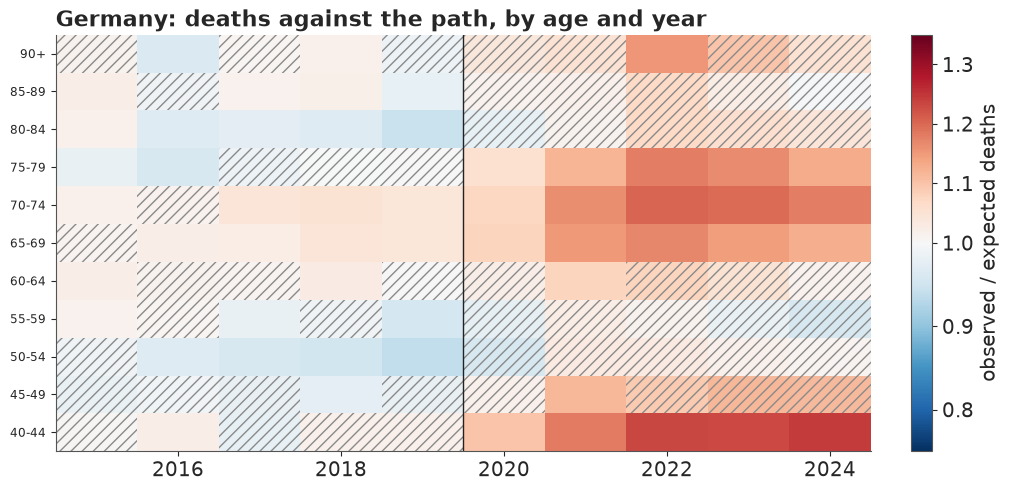

In [32]:
cD = GEOS.index("DE")
yrs_c = np.arange(2015, 2025)
m_carpet = np.concatenate([np.exp(P_main["a"][:, cD, None, :] + P_main["b"][:, cD, None, :] *
                                  P_main["k"][:, cD, -5:, None]), M_CAL[:, cD]], axis=1)  # S, 10, A
ratio = D[cD, [YI[y] for y in yrs_c]][None] / (E[cD, [YI[y] for y in yrs_c]][None] * m_carpet)
rmed = np.median(ratio, 0)
rlo, rhi = np.quantile(ratio, [0.055, 0.945], axis=0)
a0g = LABELS.index("40-44")
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.pcolormesh(yrs_c, np.arange(a0g, A), rmed[:, a0g:].T, cmap="RdBu_r",
                   norm=TwoSlopeNorm(vcenter=1, vmin=0.75, vmax=1.35), shading="nearest")
for i, y in enumerate(yrs_c):
    for j in range(a0g, A):
        if rlo[i, j] <= 1 <= rhi[i, j]:
            ax.add_patch(plt.Rectangle((y - 0.5, j - 0.5), 1, 1, fill=False, hatch="///",
                                       ec=MUTED, lw=0))
ax.axvline(2019.5, color=INK, lw=1)
ax.set_yticks(range(a0g, A), LABELS[a0g:], fontsize=8.5)
fig.colorbar(im, ax=ax, label="observed / expected deaths")
ax.set_title("Germany: deaths against the path, by age and year", loc="left")
print("Germany, observed/expected at 40-44 .. 90+ (rows 2020-2024):")
print(pd.DataFrame(rmed[5:, a0g:], index=yrs_c[5:], columns=LABELS[a0g:]).round(2).to_string())
print("share of 2020-2024 cells whose 89% range covers 1: "
      f"{((rlo <= 1) & (rhi >= 1))[5:, a0g:].mean():.2f}")
lr40 = np.log(D[cD, :, a0g] / E[cD, :, a0g])
slope = lambda y0, y1: np.polyfit(np.arange(y0, y1 + 1), lr40[YI[y0]:YI[y1] + 1], 1)[0]
print(f"Germany 40-44, observed death rate: {slope(2000, 2009):+.1%} a year in 2000-09, "
      f"{slope(2010, 2019):+.1%} in 2010-19; 2024 against 2019 "
      f"{np.exp(lr40[YI[2024]] - lr40[YI[2019]]) - 1:+.1%}; "
      f"b at 40-44 {np.median(P_main['b'][:, cD, a0g]):.3f} (Germany's largest is "
      f"{np.median(P_main['b'][:, cD], 0).max():.3f})");

At 65-79 Germany's deaths ran 13-18% above the path in 2024, after peaks of about 20% in 2022 and
2023. But the reddest band is at 40-44 (18-25% above from 2021 on), and that needs a warning.
      These ages have a large sensitivity
$b_x$ (0.07, against Germany's largest of 0.09), so the path expects them to keep improving fast.
Germany's observed death rate at 40-44 fell 4.2% a year in the 2000s and 1.6% in the 2010s, and in
2024 was 5% above its 2019 level. Part of the red there is the path's optimism, the failure the
backtest found; telling it apart needs causes of death, which these data do not have. About one
point of the excess at 60 and over in 2023-2024 may be the census break left in Germany's
populations (part A). With the shared error in the path, 58% of the 2020-2024 cells are hatched;
the 40-44 and 65-79 bands of 2021-2024 are not.

### What the public version gains, and what it costs

The forest plot answers "which country is how far below, give or take": one number per country, at
one date, with intervals whose ends look like cliffs. The fan map answers the question people ask
- where were we heading and where did we end up - with time on the axis, the path drawn rather
than implied, its uncertainty shaded so that nothing looks like a hard limit, and the geography at
a glance. The risk-equivalent cards turn a population rate into a sentence about one person; the
swarm makes a count of deaths countable.

What the public versions give up is the hard part of this notebook: none of them shows that the
path failed a test before the pandemic. That is why the plain-words block carries a separate, low
confidence statement for 2024, and why the backtest figure of part D belongs in any briefing for
people who will quote these numbers. The words carry their own traps: a headline that counted only
the countries "likely back" would report none, and readers would hear "none recovered" when the
honest answer for 13 countries is "can't tell"; and a rule with an edge at 66% puts Denmark on one
side and Portugal on the other on a difference of 1.5 points.

In [33]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'Spain alone': 9, 'Spain, free beta rows': 11, 'pooled NB 2000-2019': 75, 'backtest NB 2000-2014': 63, 'pooled Poisson 2000-2019': 21, 'total': 211}


## Summary

- **Lee-Carter in one line, and as one model.** Spain's log death rates for 2000-2019 are 97% one
  index times one age pattern. As a negative-binomial PyMC model the fit matched the SVD (drift
-0.61 against -0.62 a year), with a forecast band as wide as the classic one.
- **Census breaks needed a repair first.** Poland and Czechia (2021) and Germany (2011) have 2%
  steps in their populations; left in, they would have added 0.1-0.2 years to Poland's and
  Czechia's losses. Germany's 2023 break, hidden in the total by migration, is left in; correcting
  it would cut Germany's 2024 gap by under 0.1 years.
- **Pooling 30 countries works once the model is identifiable.** Free softmax rows gave Spain
  r_hat near 1.9 with no divergences; with zero-sum rows the pooled model has r_hat at most 1.02
  over all 1,896 free parameters. Improvement rates shrank towards Europe's (between-country sd
  0.08): Malta from -0.09 to -0.42.
- **The path failed its test before the pandemic.** Fitted to 2000-2014, its 90% fans covered 46%
  of 2015-2019, all misses below. A shared random-walk error ($\tau \approx 0.30$ years a year,
  from that one episode) widens every path; it is rough and centred on zero, so the losses below
  are more likely too high than too low.
- **Europe was about 1.3 years below its path in 2021** (0.6-1.9; *virtually certain*, >99%), from
  4.2 years in Bulgaria to 0.2-0.3 in Norway, Iceland and Sweden.
- **By 2024 the gap was about half a year: 17 countries are likely still below their path, and for
  13 we cannot tell** (45-65% still below), which fits a full recovery or a small remaining gap.
  Europe is *likely* (74%) still below, with low confidence. The split near the 66% edge is soft
  (18 and 12 with the other jump-off). The Netherlands (93%), Iceland, Germany, Austria, Norway
  and Finland are furthest below, the Nordic countries after a late loss in 2022.
- **The likelihood matters for the trend, not the headline.** Poisson intervals covered 74% of
  cells against 92.6%; the missing noise went into the period index and widened the 2024 fans from
  1.2 to 1.65 years.
- **For the public**: a graded fan per country on a tile-grid map, risk-equivalent ages (Spain
  2020: like being 1.6 years older, 0.9-2.3), a swarm of about 2 million excess deaths (0.3-3.5
  million; 0.9 million if the 2015-2019 shortfall repeated), and a carpet whose German "excess" at
  40-44 is partly the path's own optimism.

## Try it yourself

1. **Women and men.** The data file also holds `sex == "F"` and `"M"`. Fit both and compare the
   2021 losses: Aburto et al. (2022) found larger losses for men in 2020 in most countries. Does
   any country have women further below their path than men?
2. **Put the shared shock in the model.** Instead of estimating $\tau$ from the backtest, add a
   European period effect to the model, $k_{tc} = \kappa_t + k^{\text{own}}_{tc}$ with $\kappa_t$
   a random walk shared by all countries, and run the backtest again. Does it cover 90% of
   2015-2019, and how wide are its 2024 fans against the shared error used here?
3. **Damp the trend.** The 2010s slowdown suggests that improvement rates themselves decline.
   Replace the drift with a damped one, $\delta_{c,t+1} = \rho\, \delta_{ct}$ with $\rho$ near
   0.95, or fit only 2010-2019, and see how many countries are back on their path in 2024 and how
   the Netherlands' and Germany's gaps change.